In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import json
from pathlib import Path
import ijson
import pyarrow as pa
import pyarrow.parquet as pq

import time
from datetime import datetime, timezone

import duckdb

In [2]:
EDA_DIR = Path("eda_data")

df_igdb_clean = pd.read_parquet(
    EDA_DIR / "igdb_clean.parquet"
)

df_games_clean = pd.read_parquet(
    EDA_DIR / "games_clean.parquet"
)

df_sample_final = pd.read_parquet(
    EDA_DIR / "sample_final.parquet"
)

print("--- DATASETS CARGADOS ---")

print("IGDB:", df_igdb_clean.shape)
print("Main games:", df_games_clean.shape)
print("Muestra:", df_sample_final.shape)

--- DATASETS CARGADOS ---
IGDB: (386519, 21)
Main games: (236126, 21)
Muestra: (2019, 34)


In [3]:
print("--- COBERTURA TEMPORAL ---")

print("Primer año:", df_games_clean["release_year"].min())
print("Último año:", df_games_clean["release_year"].max())

print("\nJuegos por década:")

df_games_clean["decade"] = (
    df_games_clean["release_year"] // 10 * 10
)

display(
    df_games_clean["decade"]
    .value_counts()
    .sort_index()
)

--- COBERTURA TEMPORAL ---
Primer año: 1947
Último año: 2026

Juegos por década:


decade
1940         1
1950        12
1960        13
1970       617
1980      8973
1990     16391
2000     23247
2010     65528
2020    121344
Name: count, dtype: int64

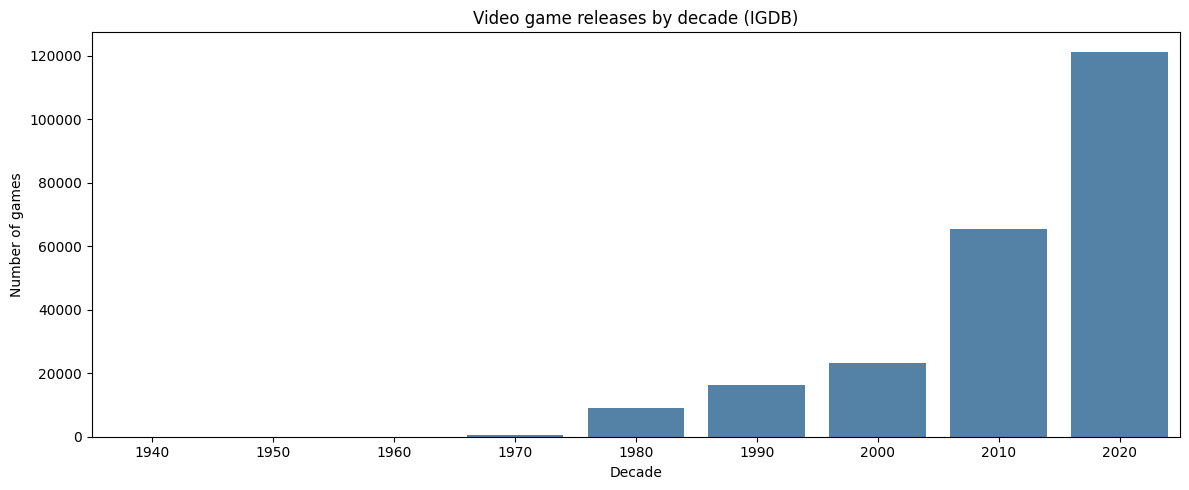

In [4]:
games_by_decade = (
    df_games_clean
    .groupby("decade")
    .size()
    .reset_index(name="games_count")
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=games_by_decade,
    x="decade",
    y="games_count",
    color="steelblue"
)

plt.title("Video game releases by decade (IGDB)")
plt.xlabel("Decade")
plt.ylabel("Number of games")

plt.tight_layout()
plt.show()

In [5]:
# Dataset auxiliar para comparar años completos
df_games_full_years = df_games_clean.loc[
    df_games_clean["release_year"] <= 2025
].copy()

print("Juegos hasta 2025:", len(df_games_full_years))

Juegos hasta 2025: 218137


In [6]:
df_releases_year = (
    df_games_full_years
    .groupby("release_year")
    .agg(games_released=("id", "nunique"))
    .reset_index()
    .sort_values("release_year")
)

display(df_releases_year.tail(15))

,release_year,games_released
57,2011,3418
58,2012,3462
59,2013,3639
60,2014,4576
61,2015,5776
62,2016,7919
63,2017,10566
64,2018,11670
65,2019,11006
66,2020,12488


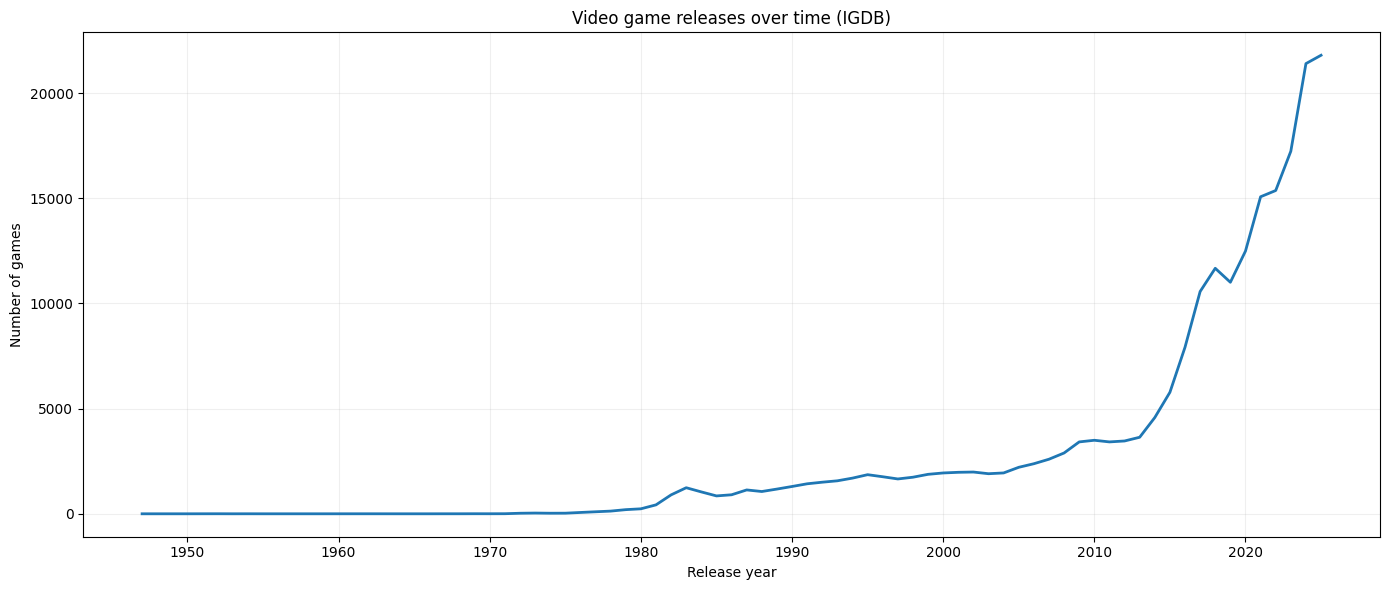

In [7]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_releases_year,
    x="release_year",
    y="games_released",
    linewidth=2
)

plt.title("Video game releases over time (IGDB)")
plt.xlabel("Release year")
plt.ylabel("Number of games")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

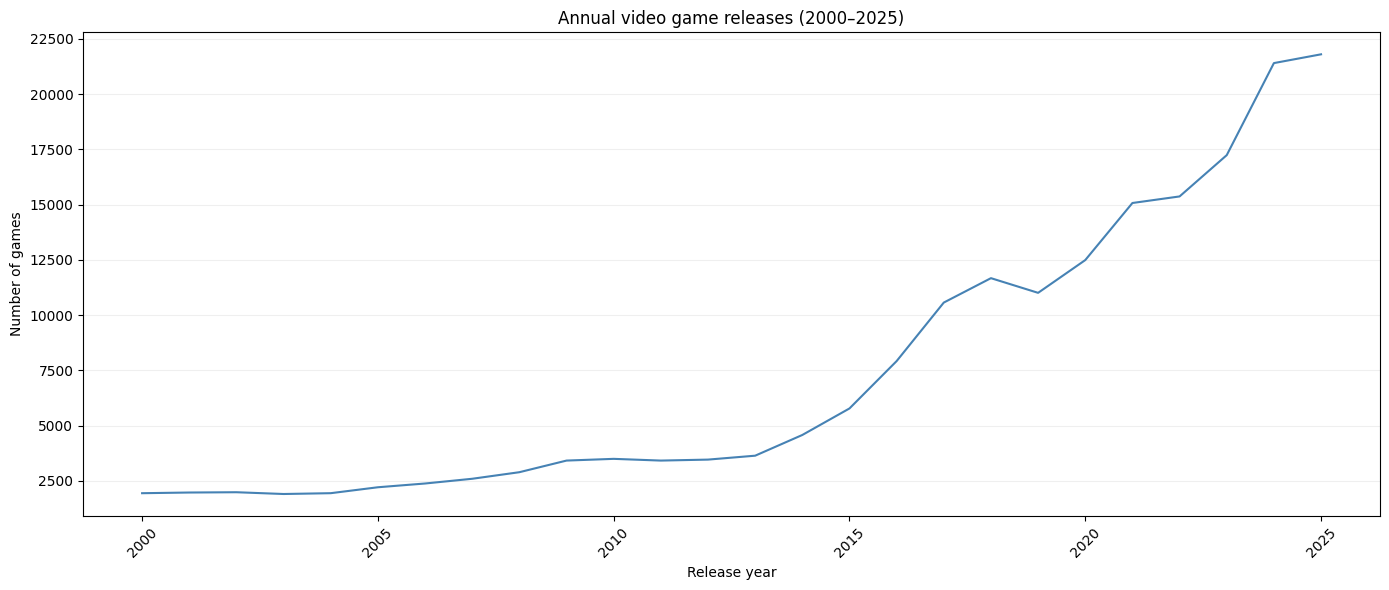

In [8]:
df_releases_2000 = df_releases_year.loc[
    df_releases_year["release_year"] >= 2000
].copy()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_releases_2000,
    x="release_year",
    y="games_released",
    color="steelblue"
)

plt.title("Annual video game releases (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Number of games")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [9]:
# Crecimiento interanual
# Crecimiento porcentual del número de lanzamientos registrados en IGDB respecto al año anterior
df_releases_year["yoy_growth_pct"] = (
    df_releases_year["games_released"]
    .pct_change() * 100
)

display(
    df_releases_year.loc[
        df_releases_year["release_year"] >= 2000
    ].tail(15)
)

,release_year,games_released,yoy_growth_pct
57,2011,3418,-2.231121
58,2012,3462,1.287303
59,2013,3639,5.112652
60,2014,4576,25.748832
61,2015,5776,26.223776
62,2016,7919,37.101801
63,2017,10566,33.425938
64,2018,11670,10.448609
65,2019,11006,-5.689803
66,2020,12488,13.465383


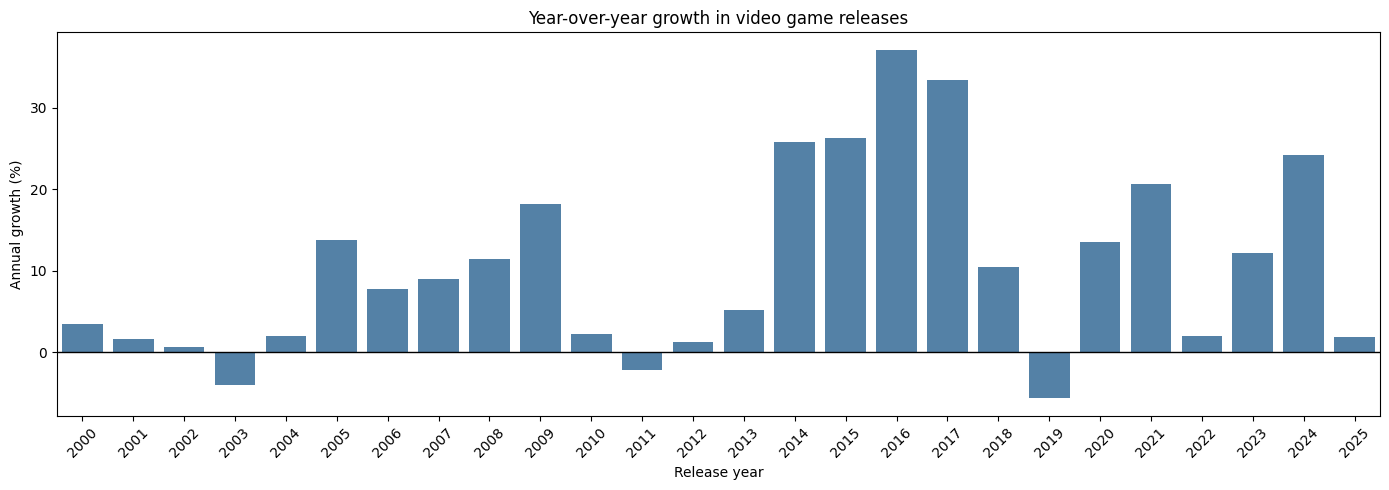

In [10]:
df_growth_2000 = df_releases_year.loc[
    df_releases_year["release_year"].between(2000, 2025)
].copy()

plt.figure(figsize=(14, 5))

sns.barplot(
    data=df_growth_2000,
    x="release_year",
    y="yoy_growth_pct",
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Year-over-year growth in video game releases")
plt.xlabel("Release year")
plt.ylabel("Annual growth (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
print("--- ANÁLISIS TEMPORAL 2000–2025 ---")

print(
    "Total de juegos:",
    df_releases_2000["games_released"].sum()
)

print(
    "Media anual:",
    round(df_releases_2000["games_released"].mean(), 2)
)

print(
    "Mediana anual:",
    df_releases_2000["games_released"].median()
)

peak_year = df_releases_2000.loc[
    df_releases_2000["games_released"].idxmax()
]

print(
    "Año con más lanzamientos:",
    int(peak_year["release_year"])
)

print(
    "Lanzamientos en ese año:",
    int(peak_year["games_released"])
)

print(
    "Crecimiento medio interanual:",
    round(df_growth_2000["yoy_growth_pct"].mean(), 2),
    "%"
)

--- ANÁLISIS TEMPORAL 2000–2025 ---
Total de juegos: 192130
Media anual: 7389.62
Mediana anual: 3567.5
Año con más lanzamientos: 2025
Lanzamientos en ese año: 21796
Crecimiento medio interanual: 10.45 %


###########################################

# Plataformas

In [12]:
df_games_platforms = (
    df_games_clean[
        ["id", "name", "release_year", "platforms_names", "is_indie"]
    ]
    .explode("platforms_names")
    .dropna(subset=["platforms_names"])
    .rename(columns={"platforms_names": "platform"})
    .copy()
)

print("--- COBERTURA DE PLATAFORMAS ---")

print("Total de videojuegos:", df_games_clean["id"].nunique())

print(
    "Juegos con plataforma:",
    df_games_platforms["id"].nunique()
)

print(
    "Juegos sin plataforma:",
    df_games_clean["id"].nunique()
    - df_games_platforms["id"].nunique()
)

print(
    "Plataformas diferentes:",
    df_games_platforms["platform"].nunique()
)

print(
    "Relaciones juego-plataforma:",
    len(df_games_platforms)
)

--- COBERTURA DE PLATAFORMAS ---
Total de videojuegos: 236126
Juegos con plataforma: 236126
Juegos sin plataforma: 0
Plataformas diferentes: 215
Relaciones juego-plataforma: 393093


In [13]:
df_platform_counts = (
    df_games_platforms
    .groupby("platform")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="games_count")
)

total_games = df_games_clean["id"].nunique()

df_platform_counts["percentage"] = (
    df_platform_counts["games_count"]
    / total_games
    * 100
).round(2)

display(df_platform_counts.head(15))

,platform,games_count,percentage
0,PC (Microsoft Windows),155658,65.92
1,Mac,29339,12.43
2,Nintendo Switch,20070,8.50
3,Linux,19668,8.33
4,iOS,17786,7.53
5,Android,17231,7.30
6,Web browser,13454,5.70
7,PlayStation 4,13134,5.56
8,Xbox One,9448,4.00
9,PlayStation 5,8873,3.76


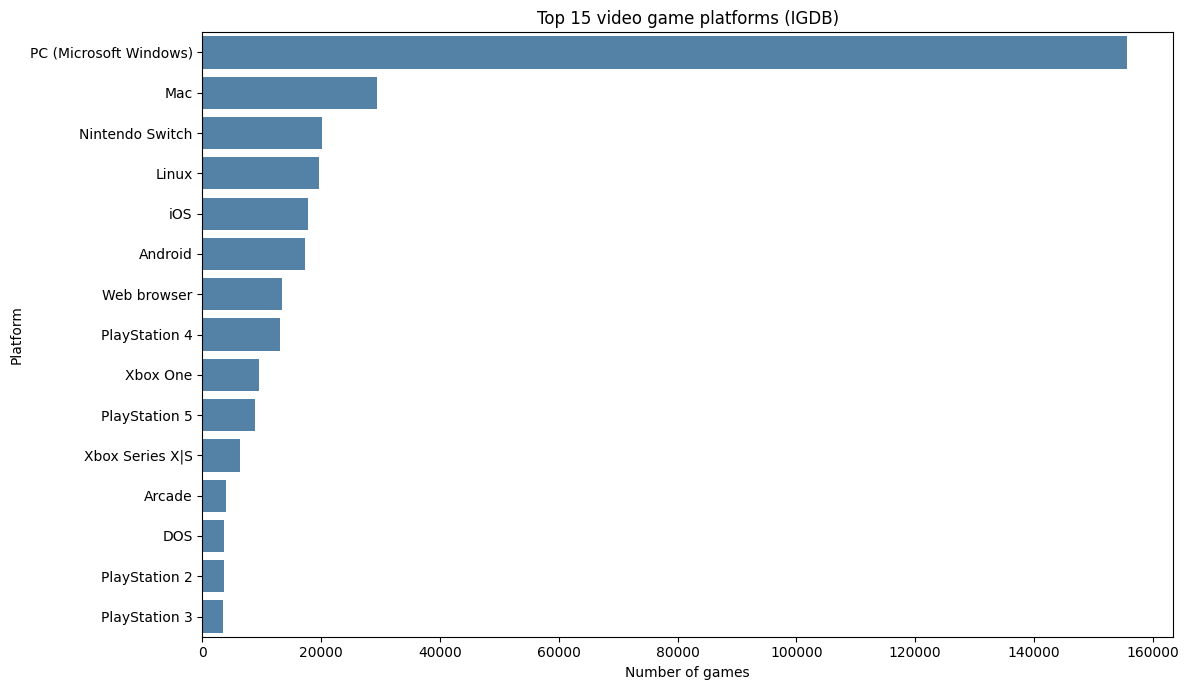

In [14]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_platform_counts.head(15),
    x="games_count",
    y="platform",
    color="steelblue"
)

plt.title("Top 15 video game platforms (IGDB)")
plt.xlabel("Number of games")
plt.ylabel("Platform")

plt.tight_layout()
plt.show()

In [15]:
df_platforms_2000 = df_games_platforms.loc[
    df_games_platforms["release_year"].between(2000, 2025)
].copy()

top_platforms = (
    df_platforms_2000["platform"]
    .value_counts()
    .head(8)
    .index
)

df_top_platforms_year = (
    df_platforms_2000.loc[
        df_platforms_2000["platform"].isin(top_platforms)
    ]
    .groupby(["release_year", "platform"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

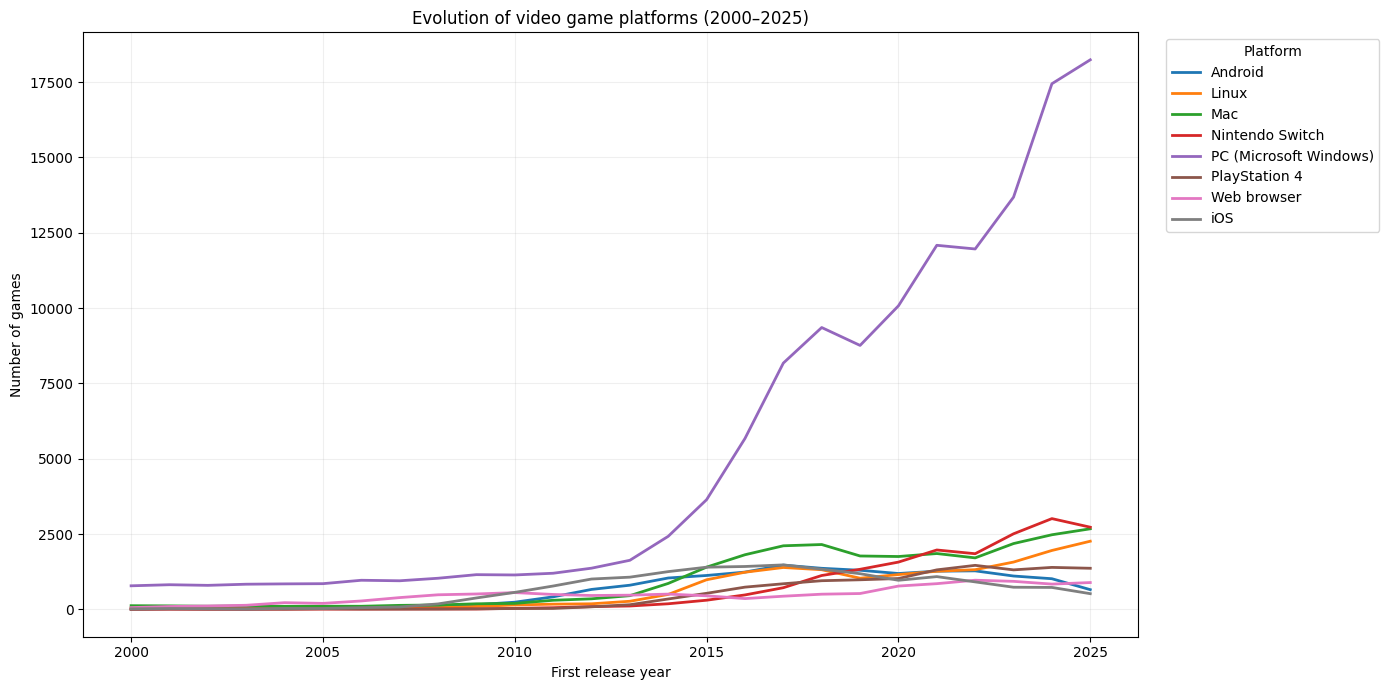

In [16]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_top_platforms_year,
    x="release_year",
    y="games_count",
    hue="platform",
    linewidth=2
)

plt.title("Evolution of video game platforms (2000–2025)")
plt.xlabel("First release year")
plt.ylabel("Number of games")

plt.legend(
    title="Platform",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [17]:
# calcularemos qué porcentaje de los videojuegos lanzados cada año está asociado a cada plataforma
games_per_year = (
    df_games_full_years.loc[
        df_games_full_years["release_year"].between(2000, 2025)
    ]
    .groupby("release_year")["id"]
    .nunique()
)

df_top_platforms_year["total_games_year"] = (
    df_top_platforms_year["release_year"]
    .map(games_per_year)
)

df_top_platforms_year["platform_share_pct"] = (
    df_top_platforms_year["games_count"]
    / df_top_platforms_year["total_games_year"]
    * 100
)

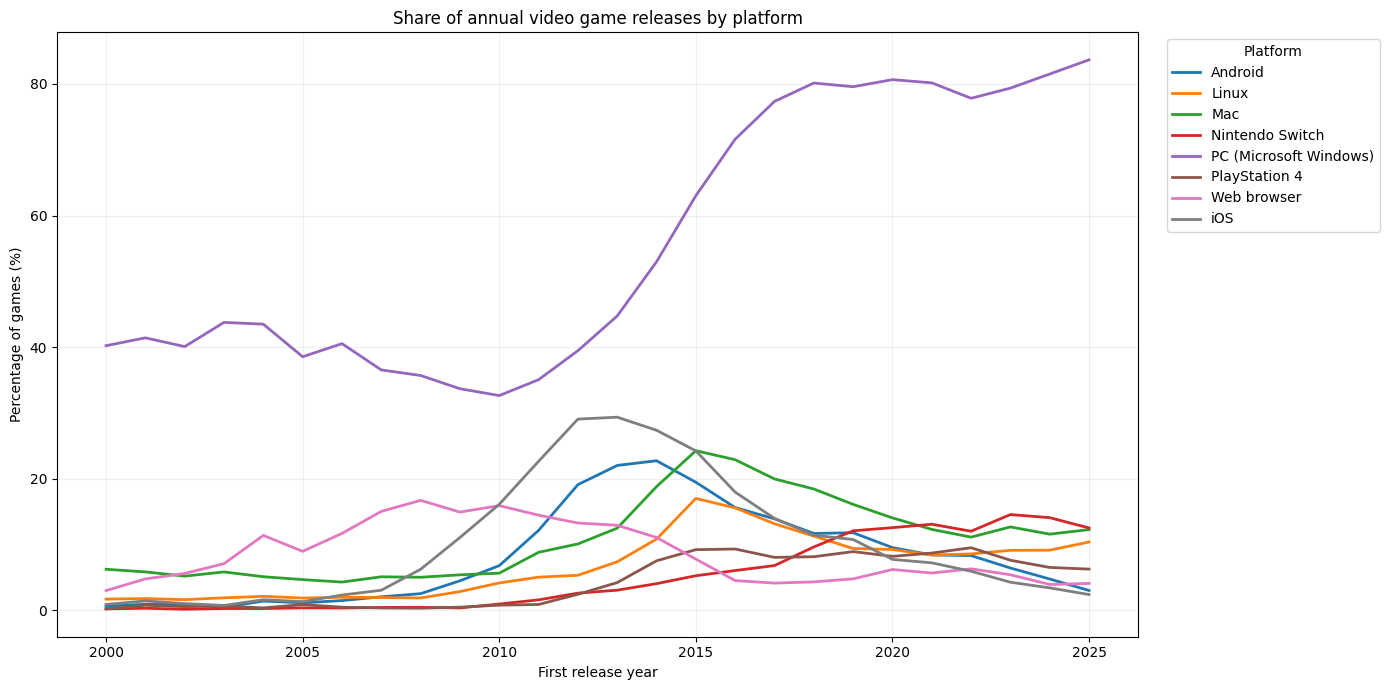

In [18]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_top_platforms_year,
    x="release_year",
    y="platform_share_pct",
    hue="platform",
    linewidth=2
)

plt.title("Share of annual video game releases by platform")
plt.xlabel("First release year")
plt.ylabel("Percentage of games (%)")

plt.legend(
    title="Platform",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [19]:
df_games_clean["platform_count"] = (
    df_games_clean["platforms_names"].apply(len)
)

print("--- PLATAFORMAS POR VIDEOJUEGO ---")

display(
    df_games_clean["platform_count"].describe()
)

print(
    "Juegos con una plataforma:",
    (df_games_clean["platform_count"] == 1).sum()
)

print(
    "Juegos multiplataforma:",
    (df_games_clean["platform_count"] > 1).sum()
)

print(
    "Juegos sin plataforma:",
    (df_games_clean["platform_count"] == 0).sum()
)

--- PLATAFORMAS POR VIDEOJUEGO ---


count    236126.000000
mean          1.664759
std           1.278269
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max          35.000000
Name: platform_count, dtype: float64

Juegos con una plataforma: 158968
Juegos multiplataforma: 77158
Juegos sin plataforma: 0


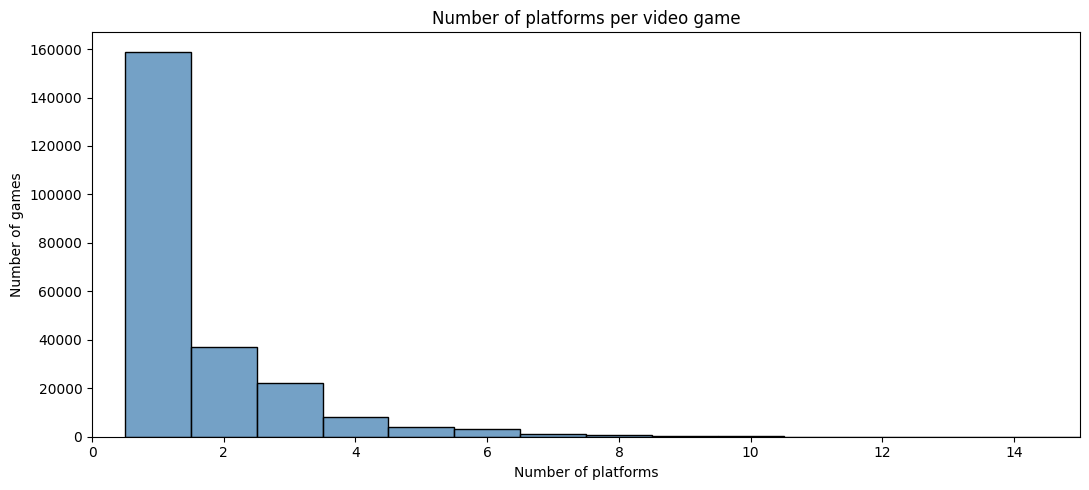

In [20]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=df_games_clean,
    x="platform_count",
    discrete=True,
    color="steelblue"
)

plt.title("Number of platforms per video game")
plt.xlabel("Number of platforms")
plt.ylabel("Number of games")

plt.xlim(0, 15)
plt.tight_layout()
plt.show()

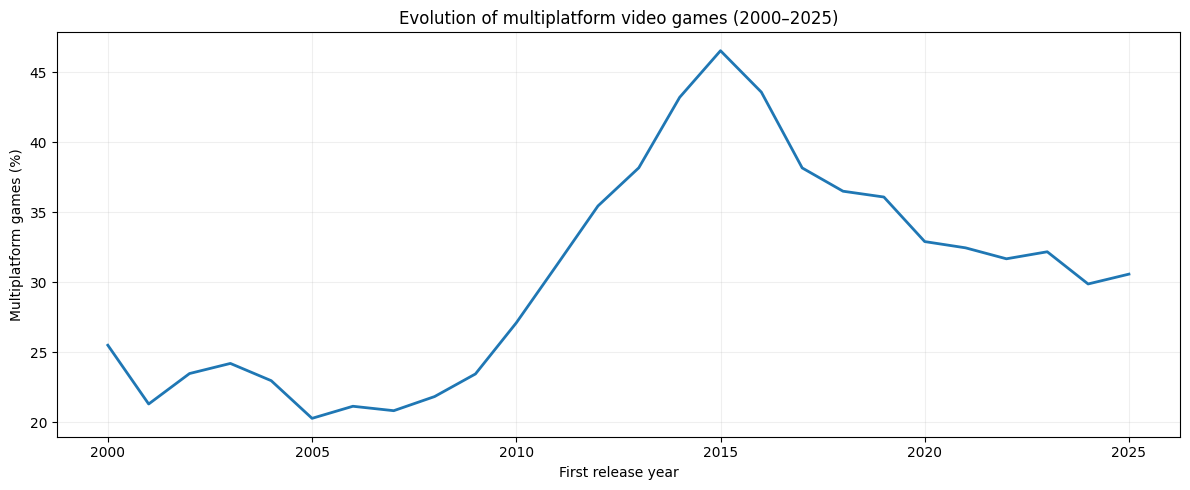

In [21]:
df_multiplatform_year = (
    df_games_clean.loc[
        df_games_clean["release_year"].between(2000, 2025)
    ]
    .groupby("release_year")
    .agg(
        total_games=("id", "nunique"),
        multiplatform_games=(
            "platform_count",
            lambda x: (x > 1).sum()
        )
    )
    .reset_index()
)

df_multiplatform_year["multiplatform_pct"] = (
    df_multiplatform_year["multiplatform_games"]
    / df_multiplatform_year["total_games"]
    * 100
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_multiplatform_year,
    x="release_year",
    y="multiplatform_pct",
    linewidth=2
)

plt.title("Evolution of multiplatform video games (2000–2025)")
plt.xlabel("First release year")
plt.ylabel("Multiplatform games (%)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Windows es la plataforma más representada en el catálogo de videojuegos principales analizado, con presencia en aproximadamente dos tercios de los títulos. Sin embargo, esta distribución no permite determinar en qué plataforma se produjo su lanzamiento original ni extrapolar directamente cuotas de mercado.

###########################################

# Game Modes

In [22]:
df_games_modes = (
    df_games_clean[
        ["id", "name", "release_year", "game_modes_names", "is_indie"]
    ]
    .explode("game_modes_names")
    .dropna(subset=["game_modes_names"])
    .rename(columns={"game_modes_names": "game_mode"})
    .copy()
)

print("--- COBERTURA DE MODOS DE JUEGO ---")

total_games = df_games_clean["id"].nunique()
games_with_modes = df_games_modes["id"].nunique()

print("Total videojuegos:", total_games)
print("Con modo de juego:", games_with_modes)
print("Sin modo de juego:", total_games - games_with_modes)
print("Cobertura:", round(games_with_modes / total_games * 100, 2), "%")
print("Modos diferentes:", df_games_modes["game_mode"].nunique())

--- COBERTURA DE MODOS DE JUEGO ---
Total videojuegos: 236126
Con modo de juego: 201138
Sin modo de juego: 34988
Cobertura: 85.18 %
Modos diferentes: 6


In [23]:
df_mode_counts = (
    df_games_modes
    .groupby("game_mode")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="games_count")
)

df_mode_counts["percentage"] = (
    df_mode_counts["games_count"] / total_games * 100
).round(2)

display(df_mode_counts)

,game_mode,games_count,percentage
0,Single player,192950,81.71
1,Multiplayer,38225,16.19
2,Co-operative,17192,7.28
3,Split screen,4296,1.82
4,Massively Multiplayer Online (MMO),3646,1.54
5,Battle Royale,545,0.23


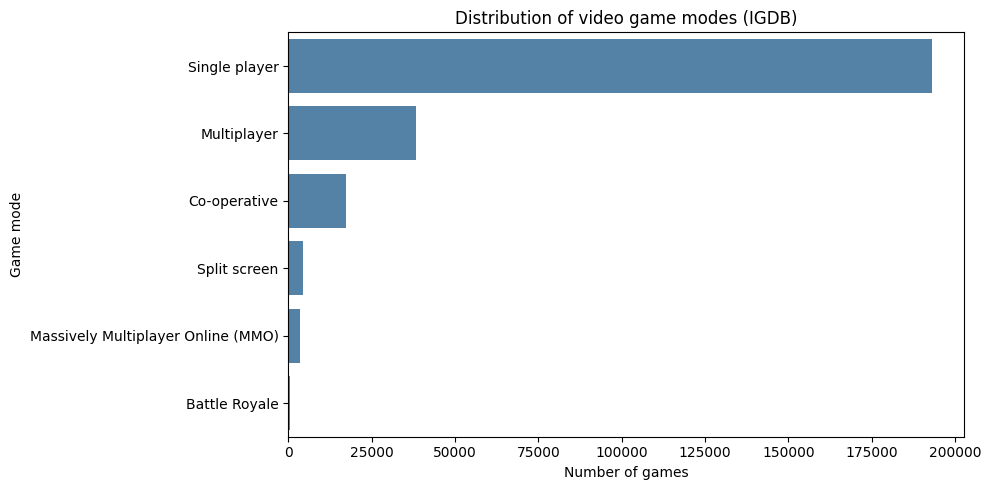

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_mode_counts,
    x="games_count",
    y="game_mode",
    color="steelblue"
)

plt.title("Distribution of video game modes (IGDB)")
plt.xlabel("Number of games")
plt.ylabel("Game mode")

plt.tight_layout()
plt.show()

In [25]:
df_modes_year = (
    df_games_modes.loc[
        df_games_modes["release_year"].between(2000, 2025)
    ]
    .groupby(["release_year", "game_mode"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

games_per_year = (
    df_games_full_years
    .loc[df_games_full_years["release_year"].between(2000, 2025)]
    .groupby("release_year")["id"]
    .nunique()
)

df_modes_year["total_games_year"] = (
    df_modes_year["release_year"].map(games_per_year)
)

df_modes_year["mode_share_pct"] = (
    df_modes_year["games_count"]
    / df_modes_year["total_games_year"]
    * 100
)

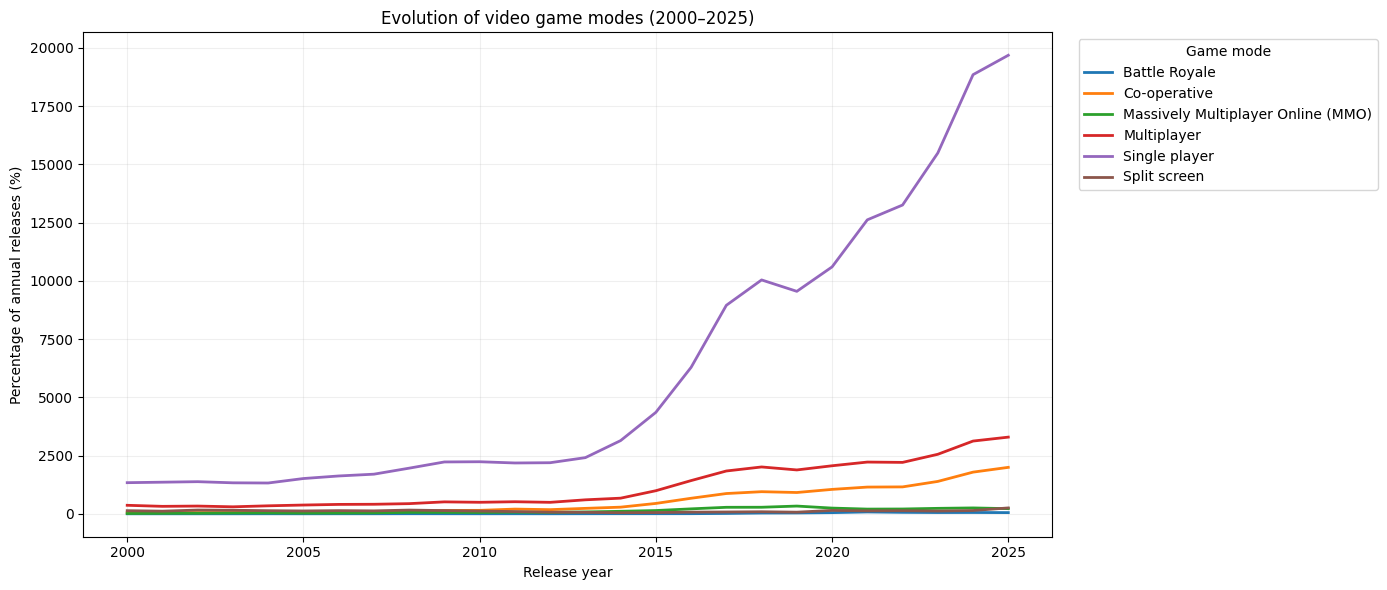

In [26]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_modes_year,
    x="release_year",
    y="games_count",
    hue="game_mode",
    linewidth=2
)

plt.title("Evolution of video game modes (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Percentage of annual releases (%)")

plt.legend(
    title="Game mode",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

###########################################

# Perspectiva del Jugador

In [27]:
df_games_perspectives = (
    df_games_clean[
        ["id", "name", "release_year", "player_perspectives_names", "is_indie"]
    ]
    .explode("player_perspectives_names")
    .dropna(subset=["player_perspectives_names"])
    .rename(columns={"player_perspectives_names": "perspective"})
    .copy()
)

print("--- COBERTURA DE PERSPECTIVAS ---")

games_with_perspective = df_games_perspectives["id"].nunique()

print("Total videojuegos:", total_games)
print("Con perspectiva:", games_with_perspective)
print("Sin perspectiva:", total_games - games_with_perspective)

print(
    "Cobertura:",
    round(games_with_perspective / total_games * 100, 2),
    "%"
)

--- COBERTURA DE PERSPECTIVAS ---
Total videojuegos: 236126
Con perspectiva: 116730
Sin perspectiva: 119396
Cobertura: 49.44 %


In [28]:
df_perspective_counts = (
    df_games_perspectives
    .groupby("perspective")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="games_count")
)

df_perspective_counts["percentage"] = (
    df_perspective_counts["games_count"]
    / total_games
    * 100
).round(2)

display(df_perspective_counts)

,perspective,games_count,percentage
0,Bird view / Isometric,33671,14.26
1,Side view,30381,12.87
2,First person,27160,11.50
3,Third person,22431,9.50
4,Text,12111,5.13
5,Virtual Reality,3939,1.67
6,Auditory,1010,0.43


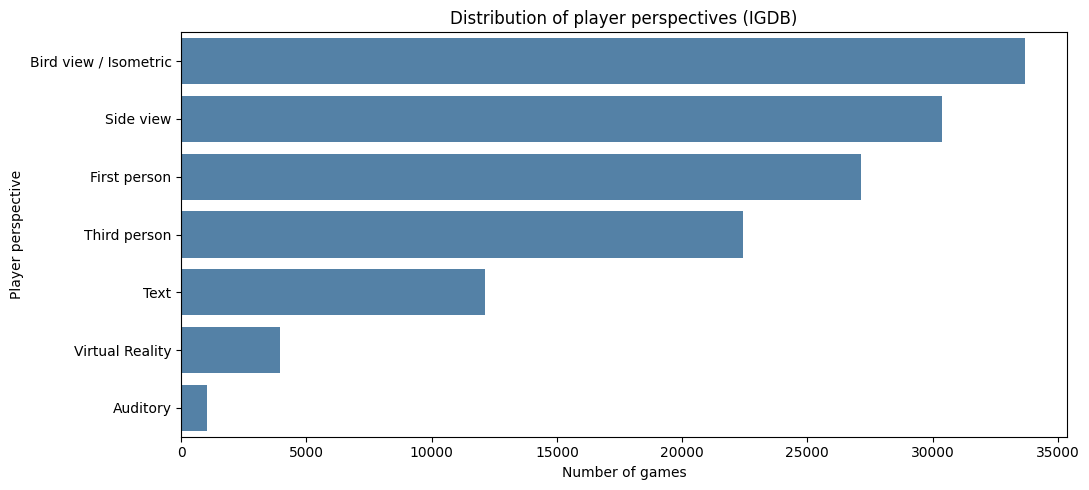

In [29]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=df_perspective_counts,
    x="games_count",
    y="perspective",
    color="steelblue"
)

plt.title("Distribution of player perspectives (IGDB)")
plt.xlabel("Number of games")
plt.ylabel("Player perspective")

plt.tight_layout()
plt.show()

In [30]:
df_perspectives_year = (
    df_games_perspectives.loc[
        df_games_perspectives["release_year"].between(2000, 2025)
    ]
    .groupby(["release_year", "perspective"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

df_perspectives_year["total_games_year"] = (
    df_perspectives_year["release_year"]
    .map(games_per_year)
)

df_perspectives_year["perspective_share_pct"] = (
    df_perspectives_year["games_count"]
    / df_perspectives_year["total_games_year"]
    * 100
)

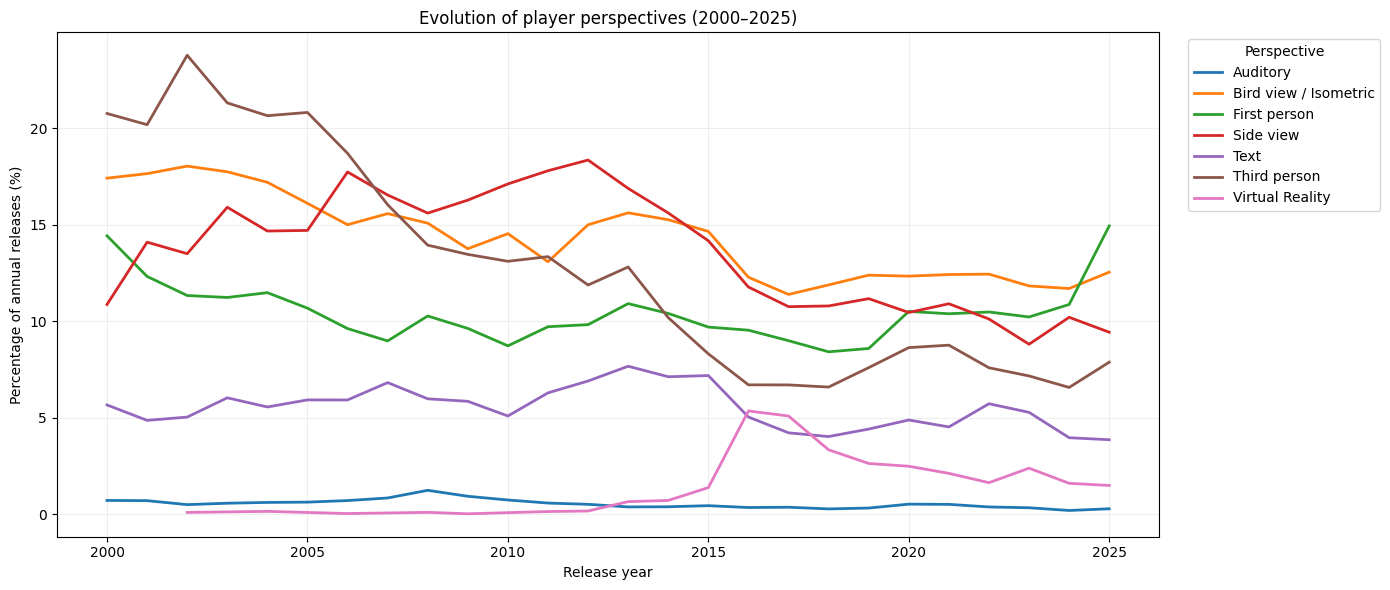

In [31]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_perspectives_year,
    x="release_year",
    y="perspective_share_pct",
    hue="perspective",
    linewidth=2
)

plt.title("Evolution of player perspectives (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Percentage of annual releases (%)")

plt.legend(
    title="Perspective",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [32]:
df_metadata_coverage = (
    df_games_full_years.loc[
        df_games_full_years["release_year"].between(2000, 2025)
    ]
    .groupby("release_year")
    .agg(
        total_games=("id", "nunique"),
        games_with_modes=(
            "game_modes_names",
            lambda s: s.apply(len).gt(0).sum()
        ),
        games_with_perspectives=(
            "player_perspectives_names",
            lambda s: s.apply(len).gt(0).sum()
        )
    )
    .reset_index()
)

df_metadata_coverage["modes_coverage_pct"] = (
    df_metadata_coverage["games_with_modes"]
    / df_metadata_coverage["total_games"] * 100
)

df_metadata_coverage["perspectives_coverage_pct"] = (
    df_metadata_coverage["games_with_perspectives"]
    / df_metadata_coverage["total_games"] * 100
)

display(df_metadata_coverage.tail(10))

,release_year,total_games,games_with_modes,games_with_perspectives,modes_coverage_pct,perspectives_coverage_pct
16,2016,7919,6598,3634,83.318601,45.889633
17,2017,10566,9378,4402,88.756388,41.661935
18,2018,11670,10546,4753,90.368466,40.728363
19,2019,11006,10047,4568,91.286571,41.504634
20,2020,12488,11101,5542,88.893338,44.378603
21,2021,15070,13232,6660,87.803583,44.193762
22,2022,15367,13880,6660,90.323420,43.339624
23,2023,17235,16215,7066,94.081810,40.997969
24,2024,21399,19678,8815,91.957568,41.193514
25,2025,21796,20546,10088,94.265003,46.283722


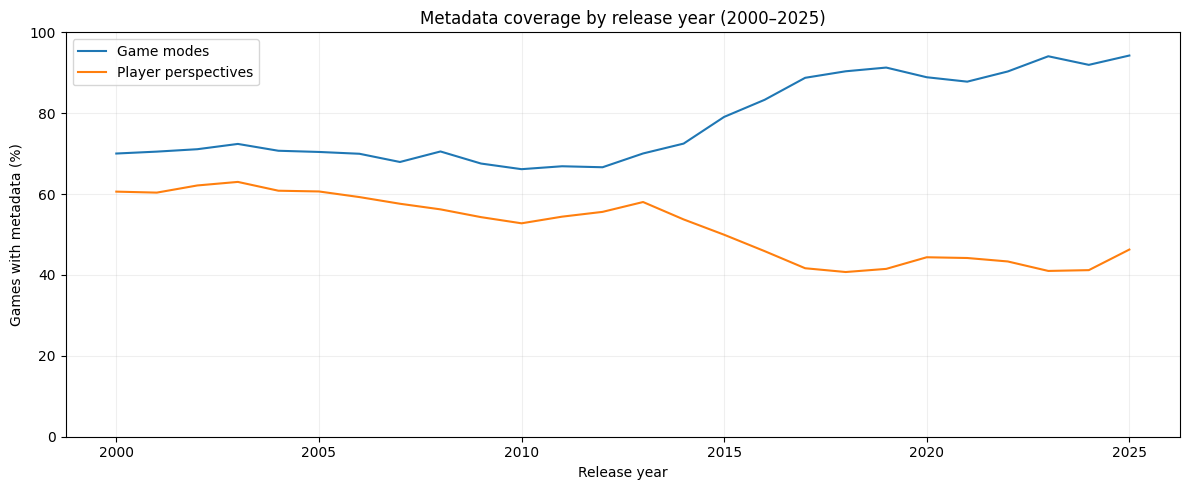

In [33]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_metadata_coverage,
    x="release_year",
    y="modes_coverage_pct",
    label="Game modes"
)

sns.lineplot(
    data=df_metadata_coverage,
    x="release_year",
    y="perspectives_coverage_pct",
    label="Player perspectives"
)

plt.title("Metadata coverage by release year (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Games with metadata (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Modos de juego: cobertura elevada y creciente
Cobertura en 2016
83,32 %

Cobertura en 2025
94,27 %

Diferencia
+10,95 pp


La cobertura de game_modes_names es bastante buena. En 2025 tenemos información de 20.546 de los 21.796 videojuegos registrados.

Esto nos permite extraer conclusiones relativamente sólidas sobre la distribución de modos de juego, aunque debemos tener en cuenta que la cobertura ha aumentado con los años.

Single player predomina claramente (81,71 % del total), mientras que Multiplayer (16,19 %) y Co-operative (7,28 %) tienen una presencia mucho menor, aunque sus tendencias temporales sean crecientes.
Perspectivas: cobertura reducida y relativamente estable
Cobertura en 2016
45,89 %

Cobertura en 2025
46,28 %

Diferencia
+0,39 pp


Aquí encontramos una limitación mucho mayor.

Durante todo el periodo, aproximadamente el 54–59 % de los videojuegos carece de información sobre la perspectiva.

Por tanto, que ninguna perspectiva supere el 15 % de los lanzamientos en 2025 no significa necesariamente que todas estén perdiendo popularidad.

Hay dos cuestiones que debemos separar:
- Presencia sobre el total de lanzamientos: mide cuántos juegos de cada año tienen registrada una perspectiva determinada.
- Presencia entre los juegos con perspectiva conocida: permite comparar cómo se distribuyen las perspectivas dentro de la parte documentada.
Por ejemplo, en 2025 tenemos 10.088 videojuegos con perspectiva conocida, de un total de 21.796. Si 3.000 tuvieran registrada la perspectiva First person, representarían el 13,76 % de todos los lanzamientos, pero el 29,74 % de los juegos con perspectiva conocida.

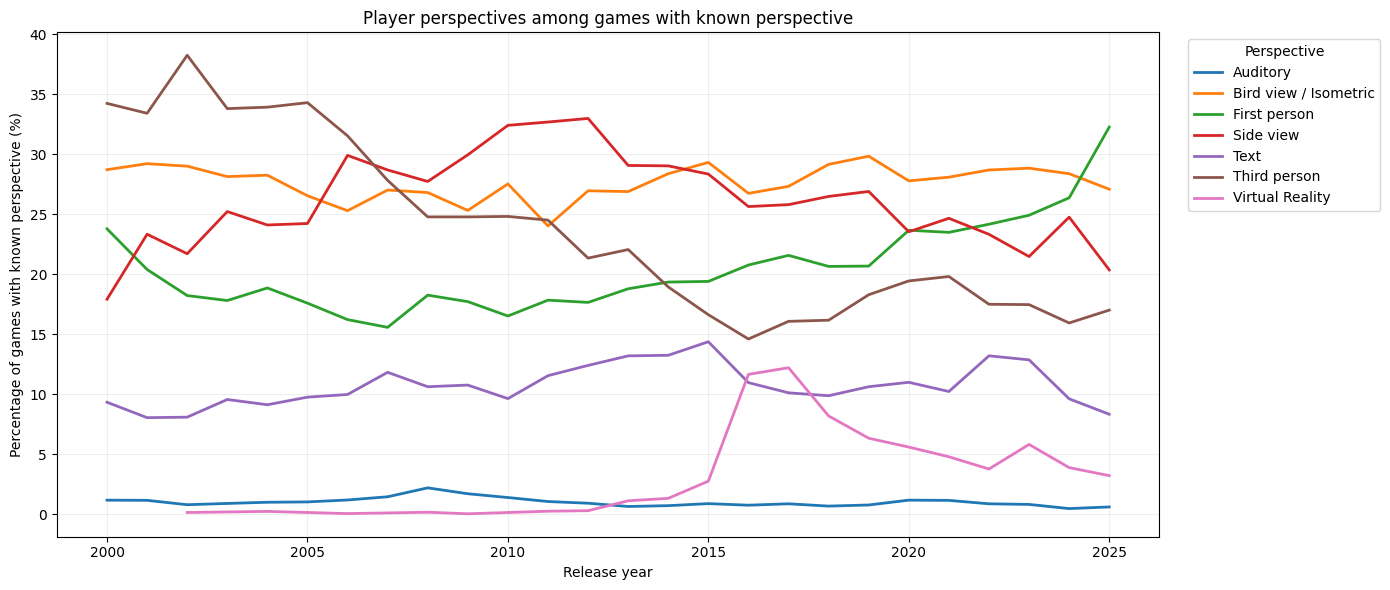

In [34]:
# Recalcular porcentajes sobre juegos con perspectiva conocida

perspectives_known_per_year = (
    df_games_perspectives
    .loc[df_games_perspectives["release_year"].between(2000, 2025)]
    .groupby("release_year")["id"]
    .nunique()
)

df_perspectives_year["games_with_perspective"] = (
    df_perspectives_year["release_year"]
    .map(perspectives_known_per_year)
)

df_perspectives_year["share_known_pct"] = (
    df_perspectives_year["games_count"]
    / df_perspectives_year["games_with_perspective"]
    * 100
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df_perspectives_year,
    x="release_year",
    y="share_known_pct",
    hue="perspective",
    linewidth=2
)

plt.title("Player perspectives among games with known perspective")
plt.xlabel("Release year")
plt.ylabel("Percentage of games with known perspective (%)")

plt.legend(title="Perspective", bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

###########################################

# Género de Videojuego

In [35]:
df_games_genres = (
    df_games_clean[
        ["id", "name", "release_year", "genres_clean", "is_indie"]
    ]
    .explode("genres_clean")
    .dropna(subset=["genres_clean"])
    .rename(columns={"genres_clean": "genre"})
    .copy()
)

print("--- COBERTURA DE GÉNEROS ---")

total_games = df_games_clean["id"].nunique()
games_with_genres = df_games_genres["id"].nunique()

print("Total videojuegos:", total_games)
print("Con género:", games_with_genres)
print("Sin género:", total_games - games_with_genres)
print("Cobertura:", round(games_with_genres / total_games * 100, 2), "%")
print("Géneros diferentes:", df_games_genres["genre"].nunique())

--- COBERTURA DE GÉNEROS ---
Total videojuegos: 236126
Con género: 198979
Sin género: 37147
Cobertura: 84.27 %
Géneros diferentes: 22


In [36]:
df_genre_counts = (
    df_games_genres
    .groupby("genre")["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="games_count")
)

df_genre_counts["percentage"] = (
    df_genre_counts["games_count"]
    / total_games
    * 100
).round(2)

display(df_genre_counts.head(15))

,genre,games_count,percentage
0,Adventure,74916,31.73
1,Simulator,40708,17.24
2,Strategy,35355,14.97
3,Role-playing (RPG),31310,13.26
4,Puzzle,28952,12.26
5,Arcade,23314,9.87
6,Shooter,18450,7.81
7,Platform,16674,7.06
8,Sport,13738,5.82
9,Visual Novel,12836,5.44


In [37]:
df_genres_2000 = df_games_genres.loc[
    df_games_genres["release_year"].between(2000, 2025)
].copy()

top_genres = (
    df_genres_2000["genre"]
    .value_counts()
    .head(8)
    .index
)

df_genres_year = (
    df_genres_2000.loc[
        df_genres_2000["genre"].isin(top_genres)
    ]
    .groupby(["release_year", "genre"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

games_per_year = (
    df_games_full_years
    .loc[df_games_full_years["release_year"].between(2000, 2025)]
    .groupby("release_year")["id"]
    .nunique()
)

df_genres_year["total_games_year"] = (
    df_genres_year["release_year"].map(games_per_year)
)

df_genres_year["genre_share_pct"] = (
    df_genres_year["games_count"]
    / df_genres_year["total_games_year"]
    * 100
)

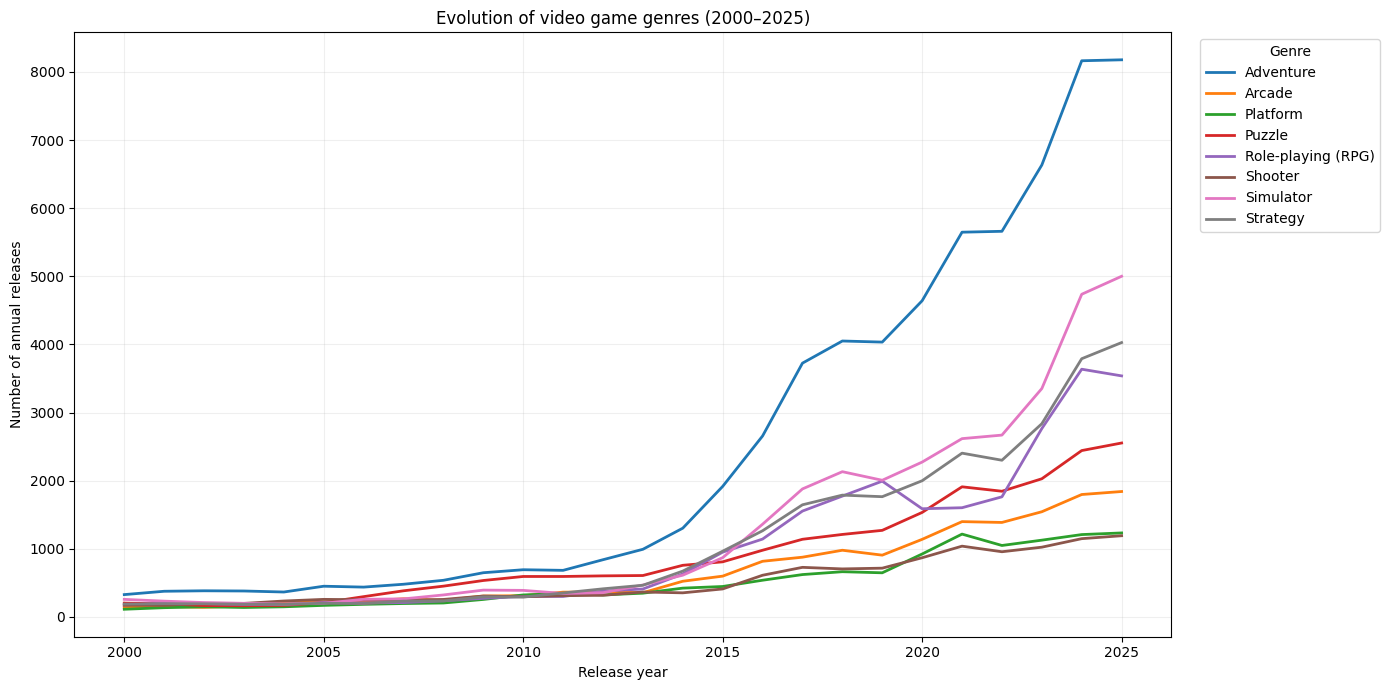

In [38]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_genres_year,
    x="release_year",
    y="games_count",
    hue="genre",
    linewidth=2
)

plt.title("Evolution of video game genres (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Number of annual releases")

plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

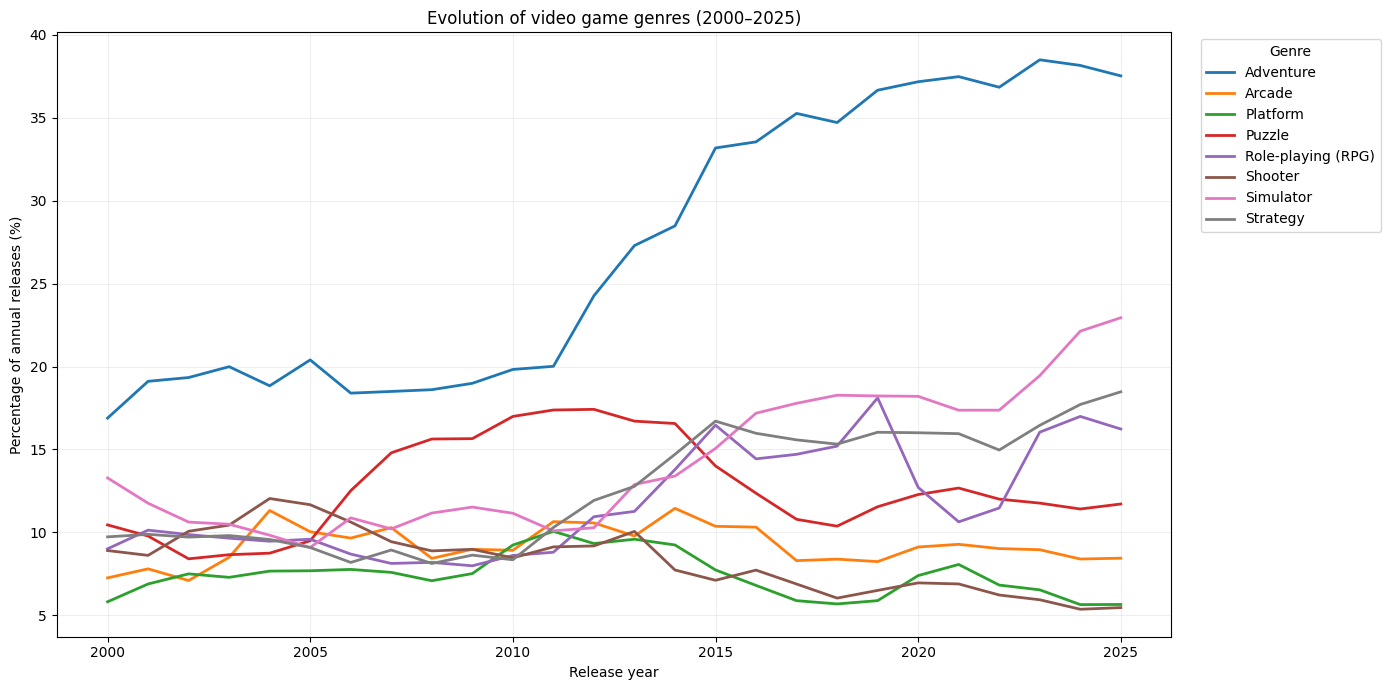

In [39]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_genres_year,
    x="release_year",
    y="genre_share_pct",
    hue="genre",
    linewidth=2
)

plt.title("Evolution of video game genres (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Percentage of annual releases (%)")

plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [40]:
df_genre_coverage = (
    df_games_full_years.loc[
        df_games_full_years["release_year"].between(2000, 2025)
    ]
    .groupby("release_year")
    .agg(
        total_games=("id", "nunique"),
        games_with_genres=(
            "genres_clean",
            lambda s: s.apply(len).gt(0).sum()
        )
    )
    .reset_index()
)

df_genre_coverage["coverage_pct"] = (
    df_genre_coverage["games_with_genres"]
    / df_genre_coverage["total_games"]
    * 100
)

display(df_genre_coverage.tail(10))

,release_year,total_games,games_with_genres,coverage_pct
16,2016,7919,6643,83.886854
17,2017,10566,8598,81.374219
18,2018,11670,9261,79.357326
19,2019,11006,9099,82.673087
20,2020,12488,10327,82.695388
21,2021,15070,12383,82.169874
22,2022,15367,12620,82.124032
23,2023,17235,14346,83.237598
24,2024,21399,17797,83.167438
25,2025,21796,18391,84.377867


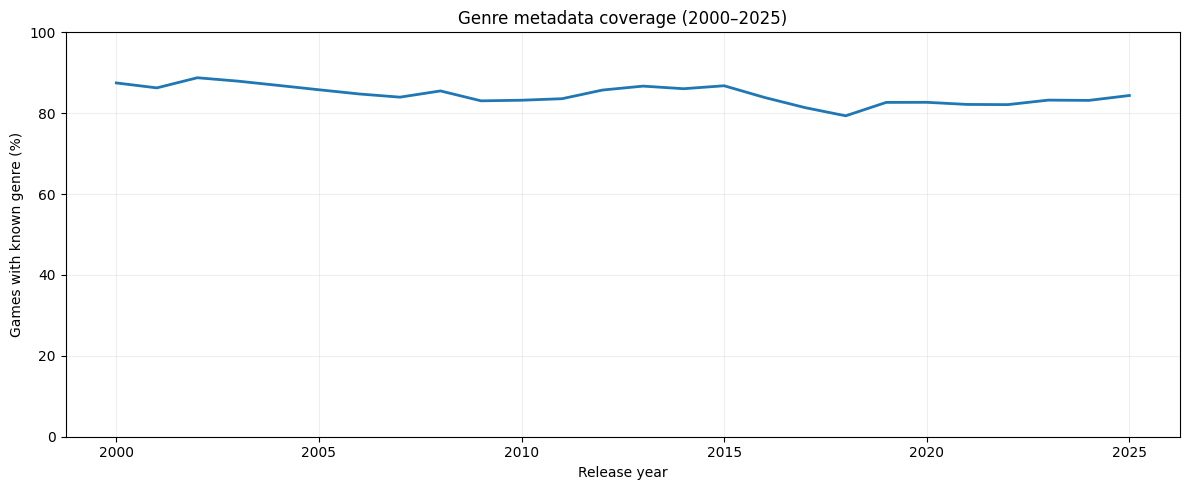

In [41]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_genre_coverage,
    x="release_year",
    y="coverage_pct",
    linewidth=2
)

plt.title("Genre metadata coverage (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Games with known genre (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Adventure domina claramente el catálogo de IGDB

Adventure (31,73 %) aparece en casi uno de cada tres videojuegos.

Simulator (17,24 %), Strategy (14,97 %) y RPG (13,26 %) forman un segundo grupo de géneros muy representados.

Shooter (7,81 %) y Platform (7,06 %) tienen una presencia menor de la que podríamos esperar si pensamos únicamente en los videojuegos comerciales más conocidos.

#######################################

# Indie Vs No Indie

In [42]:
df_indie_counts = (
    df_games_clean["is_indie"]
    .value_counts()
    .rename(index={True: "Indie", False: "No Indie label"})
    .reset_index()
)

df_indie_counts.columns = ["category", "games_count"]

df_indie_counts["percentage"] = (
    df_indie_counts["games_count"]
    / df_indie_counts["games_count"].sum()
    * 100
).round(2)

display(df_indie_counts)

,category,games_count,percentage
0,No Indie label,132012,55.91
1,Indie,104114,44.09


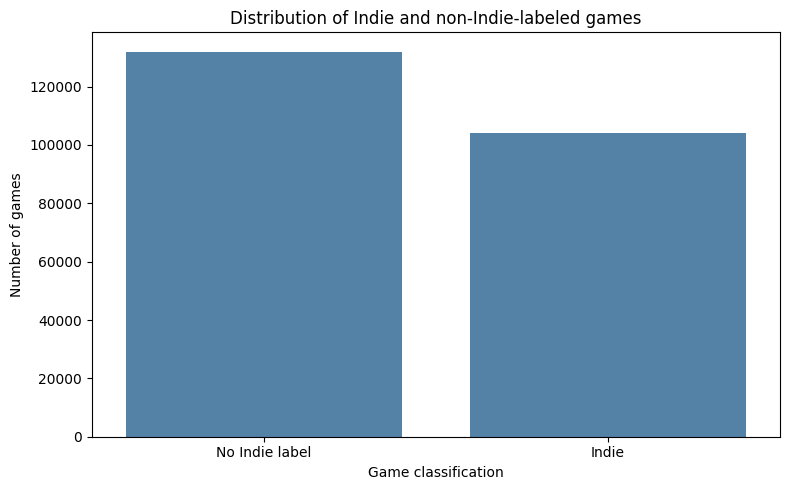

In [43]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_indie_counts,
    x="category",
    y="games_count",
    color="steelblue"
)

plt.title("Distribution of Indie and non-Indie-labeled games")
plt.xlabel("Game classification")
plt.ylabel("Number of games")

plt.tight_layout()
plt.show()

In [44]:
df_indie_year = (
    df_games_full_years.loc[
        df_games_full_years["release_year"].between(2000, 2025)
    ]
    .groupby("release_year")
    .agg(
        total_games=("id", "nunique"),
        indie_games=("is_indie", "sum")
    )
    .reset_index()
)

df_indie_year["indie_pct"] = (
    df_indie_year["indie_games"]
    / df_indie_year["total_games"]
    * 100
)

display(df_indie_year.tail(15))

,release_year,total_games,indie_games,indie_pct
11,2011,3418,434,12.697484
12,2012,3462,579,16.724437
13,2013,3639,725,19.923056
14,2014,4576,1374,30.026224
15,2015,5776,2464,42.659280
16,2016,7919,3998,50.486172
17,2017,10566,6089,57.628242
18,2018,11670,7149,61.259640
19,2019,11006,6717,61.030347
20,2020,12488,7594,60.810378


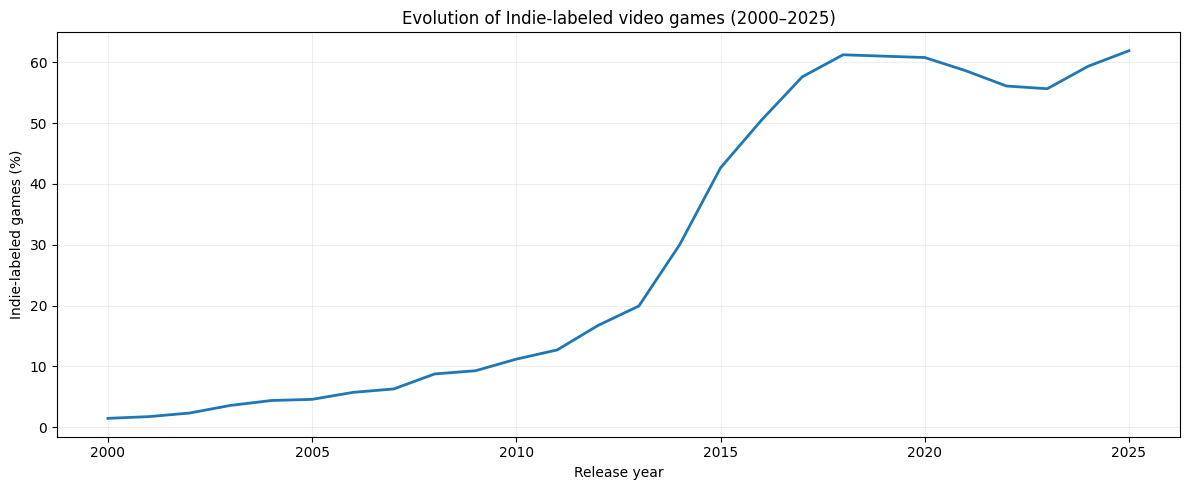

In [45]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_indie_year,
    x="release_year",
    y="indie_pct",
    linewidth=2
)

plt.title("Evolution of Indie-labeled video games (2000–2025)")
plt.xlabel("Release year")
plt.ylabel("Indie-labeled games (%)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

2011–2016: crecimiento acelerado. La proporción de juegos etiquetados Indie pasa del 12,70 % al 50,49 %. En solo cinco años aumenta aproximadamente 37,8 puntos porcentuales.

2017–2023: consolidación. La presencia Indie se mantiene por encima del 55 %, aunque presenta una ligera reducción desde el máximo del periodo alcanzado en 2018 (61,26 %).

2024–2025: recuperación. En 2025 alcanza el 61,93 %, el valor más alto de los años que has compartido. Además, el número absoluto de juegos Indie pasa de 434 en 2011 a 13.498 en 2025.

Esto sugiere una transformación importante en la composición de los lanzamientos registrados por IGDB. No obstante, también podría influir la evolución de la cobertura del catálogo y de sus etiquetas a lo largo del tiempo.

###########################################

# ¿Qué géneros predominan entre los juegos Indie?

In [46]:
df_genres_indie = (
    df_games_genres
    .groupby(["is_indie", "genre"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

# Total de videojuegos en cada grupo
total_by_indie = (
    df_games_clean
    .groupby("is_indie")["id"]
    .nunique()
)

df_genres_indie["total_group"] = (
    df_genres_indie["is_indie"].map(total_by_indie)
)

df_genres_indie["percentage"] = (
    df_genres_indie["games_count"]
    / df_genres_indie["total_group"]
    * 100
)

df_genres_indie["category"] = (
    df_genres_indie["is_indie"]
    .map({True: "Indie", False: "No Indie label"})
)

display(
    df_genres_indie
    .sort_values(["category", "games_count"], ascending=[True, False])
    .groupby("category")
    .head(10)
)

,is_indie,genre,games_count,total_group,percentage,category
22,True,Adventure,43718,104114,41.990510,Indie
38,True,Simulator,21288,104114,20.446818,Indie
40,True,Strategy,19680,104114,18.902357,Indie
36,True,Role-playing (RPG),16708,104114,16.047794,Indie
32,True,Puzzle,11919,104114,11.448028,Indie
30,True,Platform,7511,104114,7.214208,Indie
23,True,Arcade,7244,104114,6.957758,Indie
37,True,Shooter,6610,104114,6.348810,Indie
43,True,Visual Novel,4990,104114,4.792823,Indie
39,True,Sport,3909,104114,3.754538,Indie


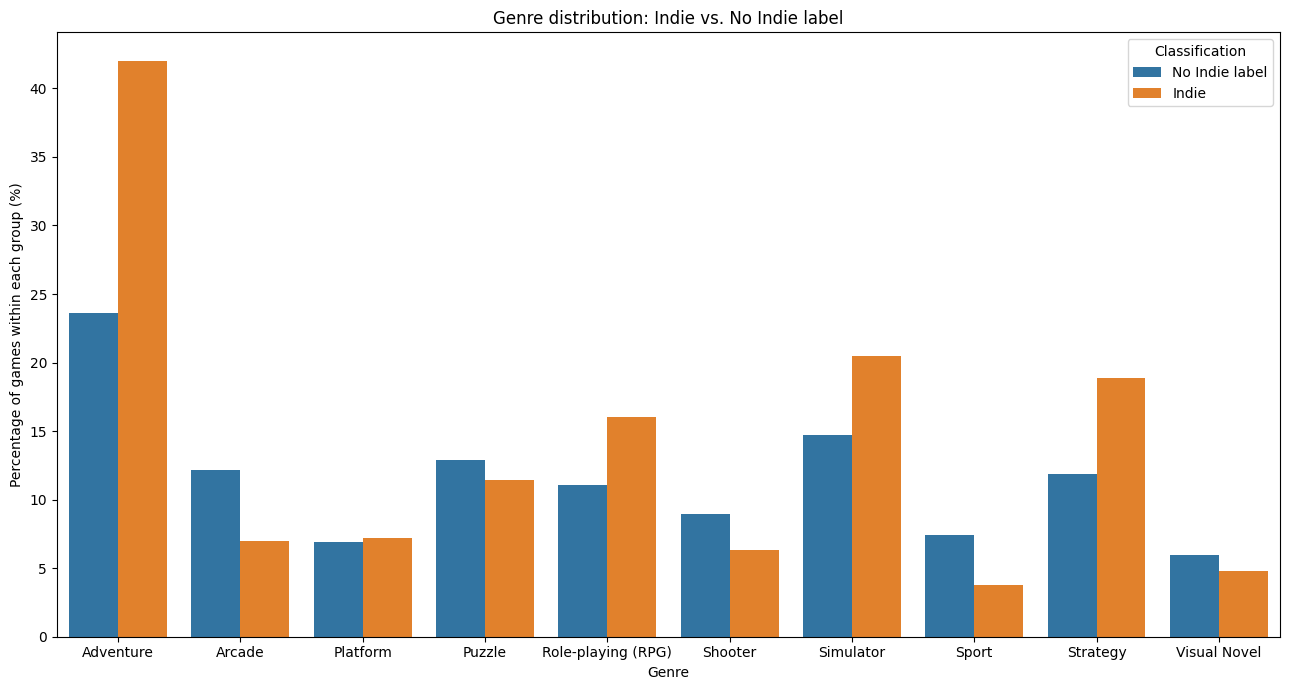

In [47]:
top_10_genres = df_genre_counts.head(10)["genre"]

df_genres_compare = df_genres_indie.loc[
    df_genres_indie["genre"].isin(top_10_genres)
].copy()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=df_genres_compare,
    x="genre",
    y="percentage",
    hue="category"
)

plt.title("Genre distribution: Indie vs. No Indie label")
plt.xlabel("Genre")
plt.ylabel("Percentage of games within each group (%)")
plt.legend(title="Classification")

plt.tight_layout()
plt.show()

In [48]:
df_genre_difference = (
    df_genres_indie
    .pivot(
        index="genre",
        columns="category",
        values="percentage"
    )
    .fillna(0)
)

df_genre_difference["difference_pp"] = (
    df_genre_difference["Indie"]
    - df_genre_difference["No Indie label"]
)

display(
    df_genre_difference
    .sort_values("difference_pp", ascending=False)
    .round(2)
)

category,Indie,No Indie label,difference_pp
genre,,,
Adventure,41.99,23.63,18.36
Strategy,18.90,11.87,7.03
Simulator,20.45,14.71,5.74
Role-playing (RPG),16.05,11.06,4.99
Platform,7.21,6.94,0.27
MOBA,0.05,0.10,-0.05
Pinball,0.06,0.28,-0.22
Tactical,1.05,1.33,-0.28
Turn-based strategy (TBS),1.39,1.88,-0.49


Interpretación de difference_pp:

- Un valor positivo significa que el género tiene mayor presencia proporcional entre los videojuegos etiquetados Indie.

- Un valor negativo indica una mayor presencia entre los videojuegos sin esa etiqueta.

Estas diferencias son descriptivas; por sí solas no demuestran asociaciones causales ni diferencias estadísticamente significativas.

In [49]:
df_genres_recent = df_games_genres.loc[
    df_games_genres["release_year"].between(2016, 2025)
].copy()

df_games_recent = df_games_clean.loc[
    df_games_clean["release_year"].between(2016, 2025)
].copy()

# Total de juegos por grupo
total_recent_by_indie = (
    df_games_recent.groupby("is_indie")["id"].nunique()
)

# Distribución de géneros por grupo
df_genres_indie_recent = (
    df_genres_recent
    .groupby(["is_indie", "genre"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

df_genres_indie_recent["total_group"] = (
    df_genres_indie_recent["is_indie"].map(total_recent_by_indie)
)

df_genres_indie_recent["percentage"] = (
    df_genres_indie_recent["games_count"]
    / df_genres_indie_recent["total_group"]
    * 100
)

df_genres_indie_recent["category"] = (
    df_genres_indie_recent["is_indie"]
    .map({True: "Indie", False: "No Indie label"})
)

In [50]:
df_genre_difference_recent = (
    df_genres_indie_recent
    .pivot(
        index="genre",
        columns="category",
        values="percentage"
    )
    .fillna(0)
)

df_genre_difference_recent["difference_pp"] = (
    df_genre_difference_recent["Indie"]
    - df_genre_difference_recent["No Indie label"]
)

display(
    df_genre_difference_recent
    .sort_values("difference_pp", ascending=False)
    .round(2)
)

category,Indie,No Indie label,difference_pp
genre,,,
Adventure,42.93,28.43,14.50
Strategy,18.36,13.81,4.55
Role-playing (RPG),15.74,13.42,2.32
Simulator,20.14,18.32,1.82
Platform,6.82,5.77,1.05
Point-and-click,2.18,2.22,-0.05
Pinball,0.05,0.13,-0.09
MOBA,0.05,0.14,-0.09
Hack and slash/Beat 'em up,1.12,1.24,-0.12


Adventure sigue siendo la diferencia más destacada. Entre 2016 y 2025, el 42,93 % de los juegos etiquetados Indie pertenece a Adventure, frente al 28,43 % de los juegos sin esa etiqueta.

Strategy también mantiene una diferencia considerable, de +4,55 puntos porcentuales.

En cambio, las diferencias de Simulator, RPG, Shooter y Sport se reducen notablemente cuando restringimos el periodo. Esto sugiere que la composición temporal de los grupos influye en la comparación histórica.

Arcade es especialmente interesante: su diferencia permanece prácticamente idéntica (−5,22 frente a −5,23 pp). Su mayor representación entre los juegos sin etiqueta Indie no parece depender únicamente de la inclusión de videojuegos antiguos.

Por último, Puzzle y Visual Novel presentan diferencias negativas más pronunciadas en el periodo reciente.

##########################################

# Indie vs. No Indie por modos de juego

In [51]:
# Filtrar modos de juego al periodo 2016–2025
df_modes_recent = df_games_modes.loc[
    df_games_modes["release_year"].between(2016, 2025)
].copy()

# Calcular videojuegos por grupo y modo
df_modes_indie = (
    df_modes_recent
    .groupby(["is_indie", "game_mode"])["id"]
    .nunique()
    .reset_index(name="games_count")
)

# Reutilizamos el total de juegos por grupo
df_modes_indie["total_group"] = (
    df_modes_indie["is_indie"].map(total_recent_by_indie)
)

df_modes_indie["percentage"] = (
    df_modes_indie["games_count"]
    / df_modes_indie["total_group"]
    * 100
)

df_modes_indie["category"] = (
    df_modes_indie["is_indie"]
    .map({True: "Indie", False: "No Indie label"})
)

display(
    df_modes_indie.sort_values(
        ["category", "games_count"],
        ascending=[True, False]
    )
)

,is_indie,game_mode,games_count,total_group,percentage,category
10,True,Single player,79990,84807,94.320044,Indie
9,True,Multiplayer,13260,84807,15.635502,Indie
7,True,Co-operative,7919,84807,9.337673,Indie
8,True,Massively Multiplayer Online (MMO),1187,84807,1.399649,Indie
11,True,Split screen,762,84807,0.898511,Indie
6,True,Battle Royale,191,84807,0.225217,Indie
4,False,Single player,45363,59709,75.973471,No Indie label
3,False,Multiplayer,9368,59709,15.689427,No Indie label
1,False,Co-operative,4014,59709,6.722605,No Indie label
2,False,Massively Multiplayer Online (MMO),1287,59709,2.155454,No Indie label


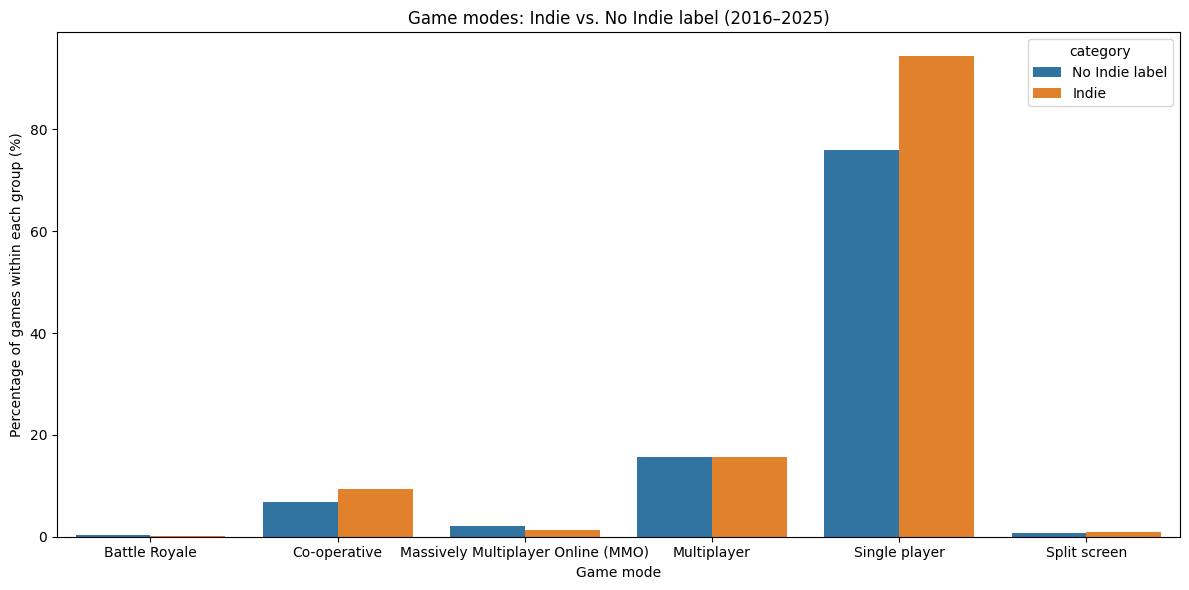

In [52]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_modes_indie,
    x="game_mode",
    y="percentage",
    hue="category"
)

plt.title("Game modes: Indie vs. No Indie label (2016–2025)")
plt.xlabel("Game mode")
plt.ylabel("Percentage of games within each group (%)")

plt.tight_layout()
plt.show()

In [53]:
df_modes_difference = (
    df_modes_indie
    .pivot(
        index="game_mode",
        columns="category",
        values="percentage"
    )
    .fillna(0)
)

df_modes_difference["difference_pp"] = (
    df_modes_difference["Indie"]
    - df_modes_difference["No Indie label"]
)

display(
    df_modes_difference
    .sort_values("difference_pp", ascending=False)
    .round(2)
)

category,Indie,No Indie label,difference_pp
game_mode,,,
Single player,94.32,75.97,18.35
Co-operative,9.34,6.72,2.62
Split screen,0.90,0.79,0.11
Multiplayer,15.64,15.69,-0.05
Battle Royale,0.23,0.44,-0.21
Massively Multiplayer Online (MMO),1.40,2.16,-0.76


In [54]:
df_modes_coverage_indie = (
    df_games_recent
    .groupby("is_indie")
    .agg(
        total_games=("id", "nunique"),
        games_with_modes=(
            "game_modes_names",
            lambda s: s.apply(len).gt(0).sum()
        )
    )
)

df_modes_coverage_indie["coverage_pct"] = (
    df_modes_coverage_indie["games_with_modes"]
    / df_modes_coverage_indie["total_games"]
    * 100
)

display(df_modes_coverage_indie.round(2))

,total_games,games_with_modes,coverage_pct
is_indie,,,
False,59709,48361,80.99
True,84807,82860,97.70


A primera vista destacaríamos tres observaciones:

- Single player: aparece mucho más frecuentemente entre los videojuegos etiquetados Indie.

- Multiplayer: prácticamente no presenta diferencias entre los grupos.

- Co-operative: tiene una presencia ligeramente mayor entre los Indie.

La diferencia es de 16,71 puntos porcentuales.

Esto significa que estamos comparando dos grupos con niveles de información muy distintos.

Por ejemplo, la diferencia de Single player podría estar parcialmente explicada por los 11.348 videojuegos sin etiqueta Indie que carecen de información sobre modos de juego, frente a solo 1.947 Indie.

In [55]:
# Denominador: juegos con modos conocidos por grupo
games_with_modes_by_indie = (
    df_modes_coverage_indie["games_with_modes"]
)

df_modes_indie_known = df_modes_indie.copy()

df_modes_indie_known["games_with_modes"] = (
    df_modes_indie_known["is_indie"]
    .map(games_with_modes_by_indie)
)

df_modes_indie_known["percentage_known"] = (
    df_modes_indie_known["games_count"]
    / df_modes_indie_known["games_with_modes"]
    * 100
)

df_modes_difference_known = (
    df_modes_indie_known
    .pivot(
        index="game_mode",
        columns="category",
        values="percentage_known"
    )
    .fillna(0)
)

df_modes_difference_known["difference_pp"] = (
    df_modes_difference_known["Indie"]
    - df_modes_difference_known["No Indie label"]
)

display(
    df_modes_difference_known
    .sort_values("difference_pp", ascending=False)
    .round(2)
)

category,Indie,No Indie label,difference_pp
game_mode,,,
Single player,96.54,93.80,2.74
Co-operative,9.56,8.30,1.26
Split screen,0.92,0.97,-0.05
Battle Royale,0.23,0.54,-0.31
Massively Multiplayer Online (MMO),1.43,2.66,-1.23
Multiplayer,16.00,19.37,-3.37


1. Los videojuegos Indie han pasado de ser minoritarios a representar más del 60 % de los lanzamientos registrados

En 2011 solo 434 videojuegos estaban etiquetados como Indie. En 2025 fueron 13.498.

Aunque existen posibles sesgos de cobertura y etiquetado en IGDB, los datos reflejan un cambio muy importante en la composición de su catálogo.

2. Adventure es el género dominante, especialmente entre los videojuegos Indie

Adventure aparece en el 31,73 % del catálogo analizado, muy por encima de Simulator (17,24 %) y Strategy (14,97 %).

Pero lo más interesante es que su presencia es mucho mayor entre los Indie, incluso cuando comparamos exclusivamente los lanzamientos de 2016–2025: 14,5 puntos porcentuales de diferencia.

Strategy también tiene mayor representación relativa entre los Indie (+4,55 pp), mientras que Arcade destaca entre los videojuegos sin etiqueta Indie (−5,23 pp).

Esto aporta una primera idea sobre cómo varía la composición de géneros según el tipo de producción

3. El multijugador crece, pero Single Player sigue siendo predominante

El 81,71 % de los videojuegos tiene registrada la modalidad Single player, frente al 16,19 % de Multiplayer y el 7,28 % de Co-operative.

Según la evolución temporal que observaste, Multiplayer y Co-operative han ganado presencia, pero continúan muy lejos de Single player.

Es una curiosidad interesante porque la visibilidad de los videojuegos multijugador populares podría hacernos pensar que ocupan una proporción mayor del catálogo.

4. Una aparente diferencia enorme entre Indie y No Indie casi desaparece cuando corregimos la cobertura

Inicialmente encontramos que Single player estaba mucho más representado entre Indie y No Indie:

Criterio de comparación	Indie	Sin etiqueta Indie	Diferencia

Todos los videojuegos, 2016–2025	94,32 %	75,97 %	+18,35 pp

Solo videojuegos con modo conocido	96,54 %	93,80 %	+2,74 pp

- ¿Por qué cambia tanto?

Porque los juegos Indie tenían una cobertura de modos del 97,70 %, frente al 80,99 % de los juegos sin etiqueta Indie.

Al utilizar únicamente juegos con modos registrados, la diferencia se reduce de manera espectacular.

Además, Multiplayer pasa de estar prácticamente empatado a tener mayor presencia relativa entre los juegos sin etiqueta Indie (19,37 % frente a 16,00 %).

Esto demuestra algo fundamental para cualquier proyecto de análisis de datos:

Una diferencia aparentemente importante puede deberse en gran parte a la ausencia desigual de información, no necesariamente a las características reales de los grupos.

5. PC domina las plataformas registradas, pero eso no significa que domine el mercado

Windows aparece asociado a casi dos tercios del catálogo analizado.

Esto es especialmente relevante teniendo en cuenta que después utilizaremos Steam como una de las principales fuentes del proyecto.

Sin embargo, hay una distinción importante: los datos describen disponibilidad en plataformas, no usuarios activos, ventas ni ingresos.

De los cinco, priorizaremos estos tres como principales resultados del análisis exploratorio de IGDB:

1. El auge de los videojuegos Indie

Es el resultado con la evolución temporal más llamativa y permite introducir cómo ha cambiado la composición del catálogo.


2. La especialización de géneros

Adventure destaca entre los Indie, mientras que otros géneros tienen mayor presencia relativa entre los juegos sin esa etiqueta.


3. El impacto de los datos incompletos

El caso de Single player demuestra por qué comprobar la cobertura de los metadatos es imprescindible antes de comparar grupos.

#######################################################

# EDA Steam Reviews

In [56]:
STEAM_PARQUET_DIR = Path("steam_etl/parquet_reviews")

con = duckdb.connect()

print(
    "Archivos Parquet:",
    len(list(STEAM_PARQUET_DIR.glob("*.parquet")))
)

Archivos Parquet: 19963


In [57]:
steam_path = (
    STEAM_PARQUET_DIR
    / "appid_*_part_*.parquet"
).as_posix()

con.execute(f"""
    CREATE OR REPLACE VIEW steam_reviews AS
    SELECT *
    FROM read_parquet(
        '{steam_path}',
        union_by_name = true
    )
""")

print("Vista steam_reviews creada correctamente")

Vista steam_reviews creada correctamente


In [58]:
df_steam_schema = con.execute("""
    DESCRIBE steam_reviews
""").df()

display(df_steam_schema)

,column_name,column_type,null,key,default,extra
0,recommendationid,VARCHAR,YES,None,None,None
1,language,VARCHAR,YES,None,None,None
2,review,VARCHAR,YES,None,None,None
3,timestamp_created,BIGINT,YES,None,None,None
4,timestamp_updated,BIGINT,YES,None,None,None
5,voted_up,BOOLEAN,YES,None,None,None
6,votes_up,BIGINT,YES,None,None,None
7,votes_funny,BIGINT,YES,None,None,None
8,weighted_vote_score,"DECIMAL(19,19)",YES,None,None,None
9,comment_count,BIGINT,YES,None,None,None


In [59]:
df_steam_preview = con.execute("""
    SELECT *
    FROM steam_reviews
    LIMIT 5
""").df()

display(df_steam_preview.T)

,0,1,2,3,4
recommendationid,219297215,210871691,199265444,195193003,192557676
language,english,schinese,schinese,english,english
review,the most overlooked mv that i own. i own about...,不好说银的部分和STG部分哪个更烂。完全不推荐。,地图拉胯，机体构筑丰富，boss战很不错,"Another game my brother assisted with, this on...",I liked this game. It has it's fair share of i...
timestamp_created,1772140814,1764165045,1751958525,1747626320,1744441840
timestamp_updated,1772140814,1764165045,1765179925,1747626320,1744441840
voted_up,True,False,True,True,True
votes_up,0,0,0,0,0
votes_funny,0,0,0,0,0
weighted_vote_score,0.5,0.5,0.5,0.5,0.5
comment_count,0,0,0,0,0


In [60]:
df_steam_overview = con.execute("""
    SELECT
        COUNT(*) AS total_reviews,
        COUNT(DISTINCT appid) AS total_games
    FROM steam_reviews
""").df()

display(df_steam_overview)

,total_reviews,total_games
0,20244155,19776


In [61]:
df_steam_games_summary = con.execute("""
    SELECT
        appid,
        COUNT(*) AS reviews_count
    FROM steam_reviews
    GROUP BY appid
    ORDER BY reviews_count DESC
""").df()

display(df_steam_games_summary.head(15))

,appid,reviews_count
0,252490,1413848
1,218620,675142
2,381210,422941
3,648800,380049
4,1293830,303540
5,1237970,289207
6,2073850,280995
7,1426210,273436
8,1222140,270721
9,698780,230023


In [62]:
print("--- REVIEWS POR VIDEOJUEGO ---")

display(
    df_steam_games_summary["reviews_count"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

--- REVIEWS POR VIDEOJUEGO ---


count    1.977600e+04
mean     1.023673e+03
std      1.438854e+04
min      1.000000e+00
25%      8.000000e+00
50%      2.600000e+01
75%      1.190000e+02
90%      6.220000e+02
95%      1.883250e+03
99%      1.522675e+04
max      1.413848e+06
Name: reviews_count, dtype: float64

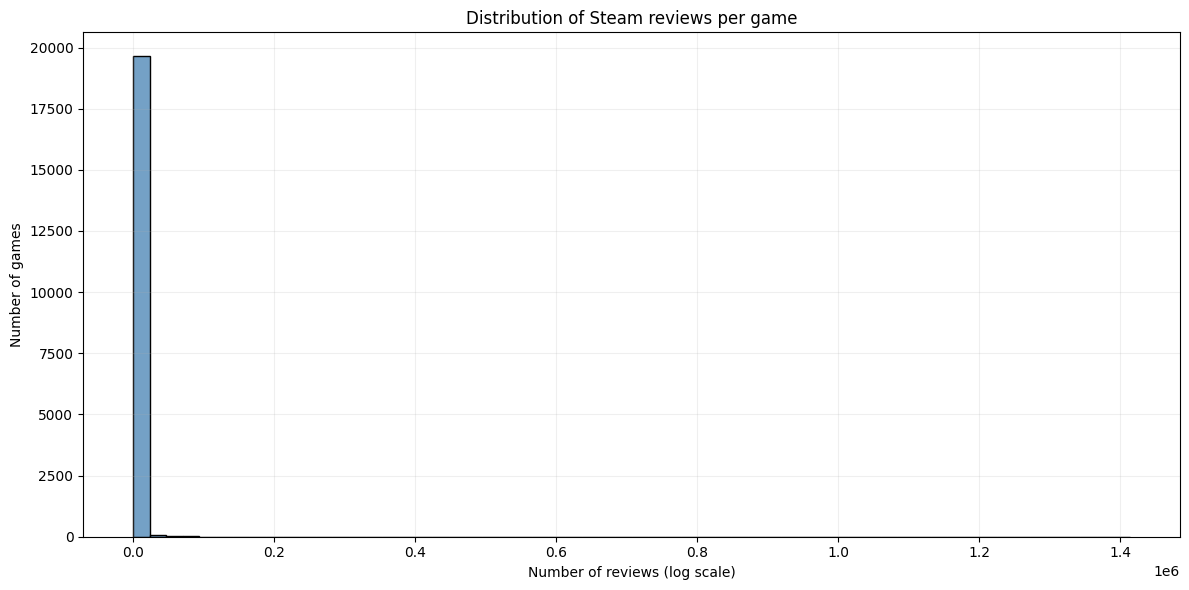

In [63]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_steam_games_summary,
    x="reviews_count",
    bins=60,
    color="steelblue"
)

# plt.xscale("log") 

plt.title("Distribution of Steam reviews per game")
plt.xlabel("Number of reviews (log scale)")
plt.ylabel("Number of games")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [64]:
df_steam_summary = pd.read_parquet(
    "eda_data/steam_reviews_summary.parquet"
)

df_steam_summary["positive_negative_sum"] = (
    df_steam_summary["total_positive"]
    + df_steam_summary["total_negative"]
)

df_steam_summary["counts_match"] = (
    df_steam_summary["positive_negative_sum"]
    == df_steam_summary["total_reviews"]
)

print("--- CALIDAD DE LOS RESÚMENES ---")

print("AppIDs únicos:", df_steam_summary["appid"].nunique())

print(
    "Sin total_reviews:",
    df_steam_summary["total_reviews"].isna().sum()
)

print(
    "Positivas + negativas = total:",
    df_steam_summary["counts_match"].sum()
)

print(
    "Resúmenes con discrepancias:",
    (
        df_steam_summary["counts_match"].eq(False)
        & df_steam_summary[
            ["total_positive", "total_negative", "total_reviews"]
        ].notna().all(axis=1)
    ).sum()
)

--- CALIDAD DE LOS RESÚMENES ---
AppIDs únicos: 27795
Sin total_reviews: 995
Positivas + negativas = total: 26800
Resúmenes con discrepancias: 0


In [65]:
df_steam_summary["reviews_difference"] = (
    df_steam_summary["total_reviews"]
    - df_steam_summary["review_count_downloaded"]
)

df_steam_summary["download_coverage_pct"] = (
    df_steam_summary["review_count_downloaded"]
    / df_steam_summary["total_reviews"]
    * 100
)

# Evitar divisiones por cero
df_steam_summary.loc[
    df_steam_summary["total_reviews"] <= 0,
    "download_coverage_pct"
] = pd.NA

print("--- COBERTURA DE EXTRACCIÓN ---")

display(
    df_steam_summary["download_coverage_pct"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print(
    "AppIDs con cobertura >= 99%:",
    (df_steam_summary["download_coverage_pct"] >= 99).sum()
)

print(
    "AppIDs con cobertura < 95%:",
    (df_steam_summary["download_coverage_pct"] < 95).sum()
)

print(
    "AppIDs con más reseñas descargadas que informadas:",
    (df_steam_summary["reviews_difference"] < 0).sum()
)

--- COBERTURA DE EXTRACCIÓN ---


count    20291.000000
mean        99.976131
std          0.737830
min         25.805798
25%        100.000000
50%        100.000000
75%        100.000000
90%        100.000000
95%        100.000000
99%        100.000000
max        103.703704
Name: download_coverage_pct, dtype: float64

AppIDs con cobertura >= 99%: 20224
AppIDs con cobertura < 95%: 17
AppIDs con más reseñas descargadas que informadas: 2


In [66]:
df_steam_summary["positive_pct"] = (
    df_steam_summary["total_positive"]
    / df_steam_summary["total_reviews"]
    * 100
)

df_steam_summary["negative_pct"] = (
    df_steam_summary["total_negative"]
    / df_steam_summary["total_reviews"]
    * 100
)

df_steam_summary.loc[
    df_steam_summary["total_reviews"] <= 0,
    ["positive_pct", "negative_pct"]
] = pd.NA

display(
    df_steam_summary[
        [
            "appid",
            "total_reviews",
            "total_positive",
            "total_negative",
            "positive_pct",
            "download_coverage_pct"
        ]
    ].head(10)
)

,appid,total_reviews,total_positive,total_negative,positive_pct,download_coverage_pct
0,1000000,43.0,35.0,8.0,81.395349,100.000000
1,1000040,1.0,0.0,1.0,0.000000,100.000000
2,1000300,NaN,NaN,NaN,NaN,NaN
3,1000360,8615.0,7605.0,1010.0,88.276262,99.988392
4,1000380,406.0,320.0,86.0,78.817734,99.753695
5,1000410,3001.0,2151.0,850.0,71.676108,99.966678
6,1000650,7.0,7.0,0.0,100.000000,100.000000
7,1000700,274.0,249.0,25.0,90.875912,100.000000
8,1000750,12.0,12.0,0.0,100.000000,100.000000
9,1000800,22.0,16.0,6.0,72.727273,100.000000


In [67]:
df_steam_validation = df_steam_summary.merge(
    df_steam_games_summary.rename(
        columns={"reviews_count": "parquet_reviews"}
    ),
    on="appid",
    how="left"
)

df_steam_validation["parquet_reviews"] = (
    df_steam_validation["parquet_reviews"].fillna(0)
)

df_steam_validation["parquet_match"] = (
    df_steam_validation["review_count_downloaded"]
    == df_steam_validation["parquet_reviews"]
)

print("--- VALIDACIÓN JSON VS PARQUET ---")

print(
    "AppIDs con recuentos coincidentes:",
    df_steam_validation["parquet_match"].sum()
)

print(
    "AppIDs con discrepancias:",
    (~df_steam_validation["parquet_match"]).sum()
)

display(
    df_steam_validation.loc[
        ~df_steam_validation["parquet_match"],
        [
            "appid",
            "review_count_downloaded",
            "parquet_reviews"
        ]
    ].head(20)
)

--- VALIDACIÓN JSON VS PARQUET ---
AppIDs con recuentos coincidentes: 27280
AppIDs con discrepancias: 515


,appid,review_count_downloaded,parquet_reviews
41,1005790,35,0.0
72,1010133,26,0.0
80,1012102,96,0.0
108,1017030,526,0.0
130,10196,136,0.0
224,1032410,14,0.0
393,1056629,1,0.0
396,105700,141,0.0
444,1063020,26,0.0
492,1067590,111,0.0


In [68]:
df_steam_validation["in_parquet"] = (
    df_steam_validation["appid"].isin(
        df_steam_games_summary["appid"]
    )
)

df_discrepancies = df_steam_validation.loc[
    ~df_steam_validation["parquet_match"]
].copy()

print("--- DISCREPANCIAS JSON VS PARQUET ---")

print("Total discrepancias:", len(df_discrepancies))

print(
    "AppIDs ausentes de Parquet:",
    (~df_discrepancies["in_parquet"]).sum()
)

print(
    "AppIDs presentes con recuento diferente:",
    df_discrepancies["in_parquet"].sum()
)

--- DISCREPANCIAS JSON VS PARQUET ---
Total discrepancias: 515
AppIDs ausentes de Parquet: 515
AppIDs presentes con recuento diferente: 0


In [69]:
df_parquet_manifest = pd.read_csv(
    "steam_etl/parquet_reviews/parquet_manifest.csv"
)

df_manifest_status = (
    df_parquet_manifest[
        ["appid", "status", "reviews_converted", "parquet_parts"]
    ]
    .drop_duplicates(subset=["appid"], keep="last")
)

df_discrepancies = df_discrepancies.merge(
    df_manifest_status,
    on="appid",
    how="left"
)

display(
    df_discrepancies.groupby(
        ["in_parquet", "status"],
        dropna=False
    ).size().reset_index(name="games_count")
)

,in_parquet,status,games_count
0,False,NaN,515


In [70]:
df_steam_eda = df_steam_summary.merge(
    df_steam_games_summary.rename(
        columns={"reviews_count": "parquet_reviews"}
    ),
    on="appid",
    how="left",
    validate="one_to_one"
)

df_steam_eda["in_parquet"] = (
    df_steam_eda["parquet_reviews"].notna()
)

df_steam_eda["parquet_reviews"] = (
    df_steam_eda["parquet_reviews"]
    .fillna(0)
    .astype("int64")
)

# Porcentaje de reseñas positivas
df_steam_eda["positive_pct"] = (
    df_steam_eda["total_positive"]
    / df_steam_eda["total_reviews"]
    * 100
)

# Cobertura de descarga
df_steam_eda["download_coverage_pct"] = (
    df_steam_eda["review_count_downloaded"]
    / df_steam_eda["total_reviews"]
    * 100
)

# Evitar divisiones por cero
df_steam_eda.loc[
    df_steam_eda["total_reviews"].le(0),
    ["positive_pct", "download_coverage_pct"]
] = float("nan")

# Validación de la conversión
df_steam_eda["parquet_match"] = (
    df_steam_eda["review_count_downloaded"]
    == df_steam_eda["parquet_reviews"]
)

display(df_steam_eda.head())

,appid,extracted_at,total_positive,total_negative,total_reviews,review_count_downloaded,positive_pct,positive_negative_sum,counts_match,reviews_difference,download_coverage_pct,negative_pct,parquet_reviews,in_parquet,parquet_match
0,1000000,2026-11-09T21:27:55.255411+00:00,35.0,8.0,43.0,43,81.395349,43.0,True,0.0,100.000000,18.604651,43,True,True
1,1000040,2026-11-09T04:19:10.176038+00:00,0.0,1.0,1.0,1,0.000000,1.0,True,0.0,100.000000,100.000000,1,True,True
2,1000300,2026-11-10T13:45:22.070346+00:00,NaN,NaN,NaN,0,NaN,NaN,False,NaN,NaN,NaN,0,False,True
3,1000360,2026-11-09T22:26:32.895578+00:00,7605.0,1010.0,8615.0,8614,88.276262,8615.0,True,1.0,99.988392,11.723738,8614,True,True
4,1000380,2026-11-07T00:34:36.065530+00:00,320.0,86.0,406.0,405,78.817734,406.0,True,1.0,99.753695,21.182266,405,True,True


In [71]:
EDA_DIR = Path("eda_data")
EDA_DIR.mkdir(parents=True, exist_ok=True)

df_steam_eda.to_parquet(
    EDA_DIR / "steam_reviews_summary_table.parquet",
    index=False
)

print(
    "Tabla Steam guardada:",
    df_steam_eda.shape
)

Tabla Steam guardada: (27795, 15)


In [72]:
df_missing_parquet = df_discrepancies.loc[
    ~df_discrepancies["in_parquet"]
].copy()

print("--- APPIDS AUSENTES DE PARQUET ---")

print("Total:", len(df_missing_parquet))

print(
    "Con reseñas descargadas:",
    (df_missing_parquet["review_count_downloaded"] > 0).sum()
)

print(
    "Sin reseñas descargadas:",
    (df_missing_parquet["review_count_downloaded"] == 0).sum()
)

print(
    "Sin recuento disponible:",
    df_missing_parquet["review_count_downloaded"].isna().sum()
)

print(
    "Reseñas potencialmente pendientes:",
    df_missing_parquet["review_count_downloaded"].sum()
)

--- APPIDS AUSENTES DE PARQUET ---
Total: 515
Con reseñas descargadas: 515
Sin reseñas descargadas: 0
Sin recuento disponible: 0
Reseñas potencialmente pendientes: 130152


In [73]:
df_steam_rated = df_steam_eda.loc[
    df_steam_eda["total_reviews"].ge(100)
    & df_steam_eda["positive_pct"].between(0, 100)
].copy()

print("--- VIDEOJUEGOS CON 100+ RESEÑAS ---")

print("Total videojuegos:", len(df_steam_rated))

display(
    df_steam_rated["positive_pct"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

--- VIDEOJUEGOS CON 100+ RESEÑAS ---
Total videojuegos: 5518


count    5518.000000
mean       79.186768
std        15.312277
min         9.401709
10%        57.899630
25%        71.155647
50%        82.754547
75%        90.979814
90%        95.214154
max       100.000000
Name: positive_pct, dtype: float64

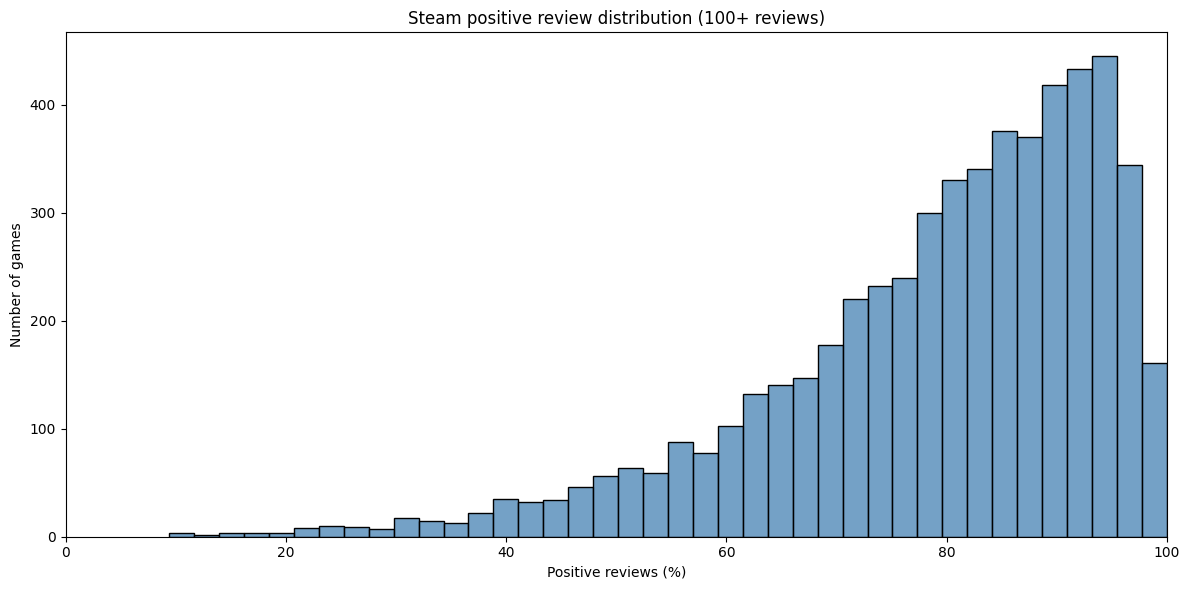

In [74]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_steam_rated,
    x="positive_pct",
    bins=40,
    color="steelblue"
)

plt.title("Steam positive review distribution (100+ reviews)")
plt.xlabel("Positive reviews (%)")
plt.ylabel("Number of games")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [75]:
# Juegos con porcentaje de valoraciones válido
df_steam_valid = df_steam_eda.loc[
    df_steam_eda["total_reviews"].gt(0)
    & df_steam_eda["positive_pct"].between(0, 100)
].copy()

# Juegos con al menos 100 reseñas
df_steam_100 = df_steam_valid.loc[
    df_steam_valid["total_reviews"] >= 100
].copy()

print("--- COBERTURA DEL ANÁLISIS ---")
print("AppIDs totales:", len(df_steam_eda))
print("Con valoraciones válidas:", len(df_steam_valid))
print("Con al menos 100 reseñas:", len(df_steam_100))

--- COBERTURA DEL ANÁLISIS ---
AppIDs totales: 27795
Con valoraciones válidas: 20291
Con al menos 100 reseñas: 5518


In [76]:
print("--- TODOS LOS JUEGOS CON RESEÑAS ---")

display(
    df_steam_valid["positive_pct"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

print("\n--- JUEGOS CON 100+ RESEÑAS ---")

display(
    df_steam_100["positive_pct"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

--- TODOS LOS JUEGOS CON RESEÑAS ---


count    20291.000000
mean        76.397157
std         22.709248
min          0.000000
10%         46.666667
25%         65.789474
50%         81.944444
75%         93.910636
90%        100.000000
max        100.000000
Name: positive_pct, dtype: float64


--- JUEGOS CON 100+ RESEÑAS ---


count    5518.000000
mean       79.186768
std        15.312277
min         9.401709
10%        57.899630
25%        71.155647
50%        82.754547
75%        90.979814
90%        95.214154
max       100.000000
Name: positive_pct, dtype: float64

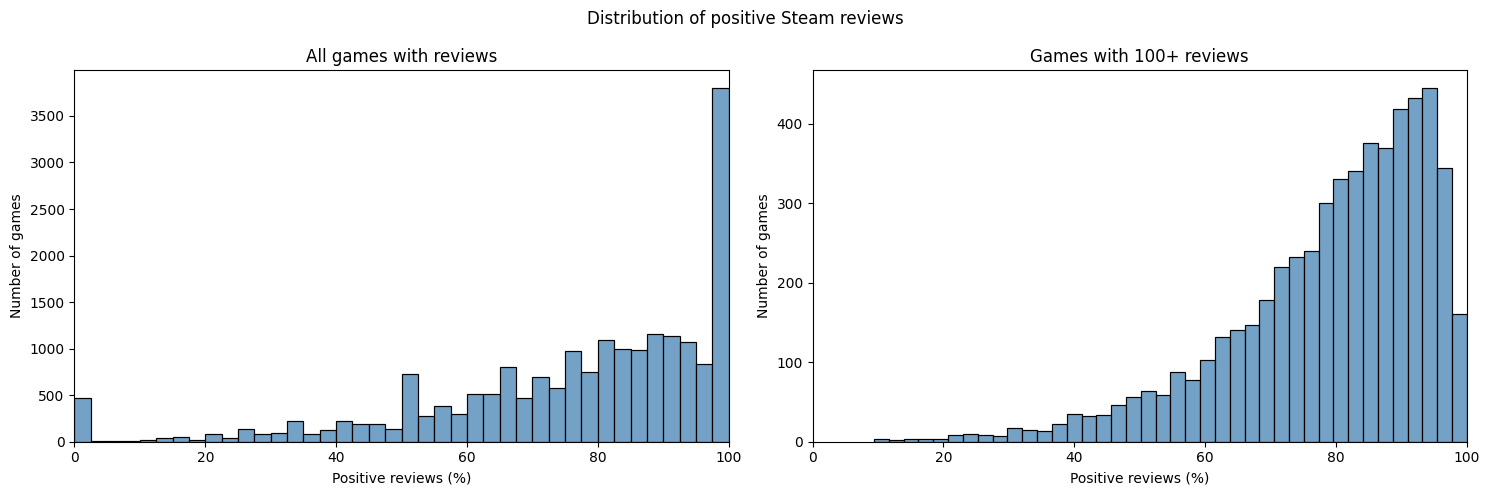

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df_steam_valid,
    x="positive_pct",
    bins=40,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("All games with reviews")
axes[0].set_xlabel("Positive reviews (%)")
axes[0].set_ylabel("Number of games")
axes[0].set_xlim(0, 100)

sns.histplot(
    data=df_steam_100,
    x="positive_pct",
    bins=40,
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Games with 100+ reviews")
axes[1].set_xlabel("Positive reviews (%)")
axes[1].set_ylabel("Number of games")
axes[1].set_xlim(0, 100)

plt.suptitle("Distribution of positive Steam reviews")
plt.tight_layout()
plt.show()

In [78]:
df_steam_100["rating_category"] = pd.cut(
    df_steam_100["positive_pct"],
    bins=[-0.01, 20, 40, 70, 90, 100],
    labels=[
        "Very Negative",
        "Mostly Negative",
        "Mixed",
        "Mostly Positive",
        "Very Positive"
    ],
    right=False,
    include_lowest=True
)

# Incluir explícitamente el 100%
df_steam_100.loc[
    df_steam_100["positive_pct"] == 100,
    "rating_category"
] = "Very Positive"

df_rating_distribution = (
    df_steam_100["rating_category"]
    .value_counts(sort=False)
    .reset_index()
)

df_rating_distribution.columns = [
    "rating_category",
    "games_count"
]

df_rating_distribution["percentage"] = (
    df_rating_distribution["games_count"]
    / len(df_steam_100)
    * 100
).round(2)

display(df_rating_distribution)

,rating_category,games_count,percentage
0,Very Negative,12,0.22
1,Mostly Negative,121,2.19
2,Mixed,1126,20.41
3,Mostly Positive,2704,49.00
4,Very Positive,1555,28.18


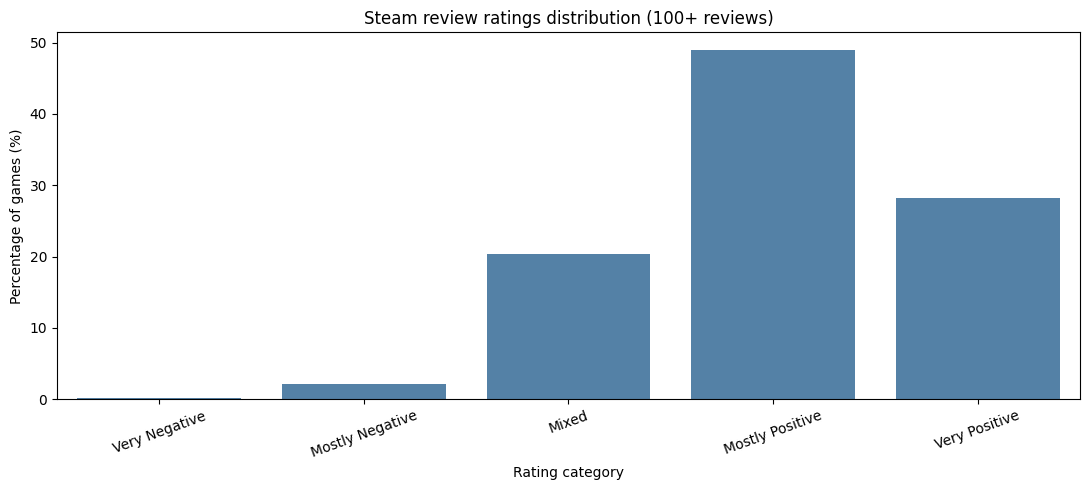

In [79]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=df_rating_distribution,
    x="rating_category",
    y="percentage",
    color="steelblue"
)

plt.title("Steam review ratings distribution (100+ reviews)")
plt.xlabel("Rating category")
plt.ylabel("Percentage of games (%)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

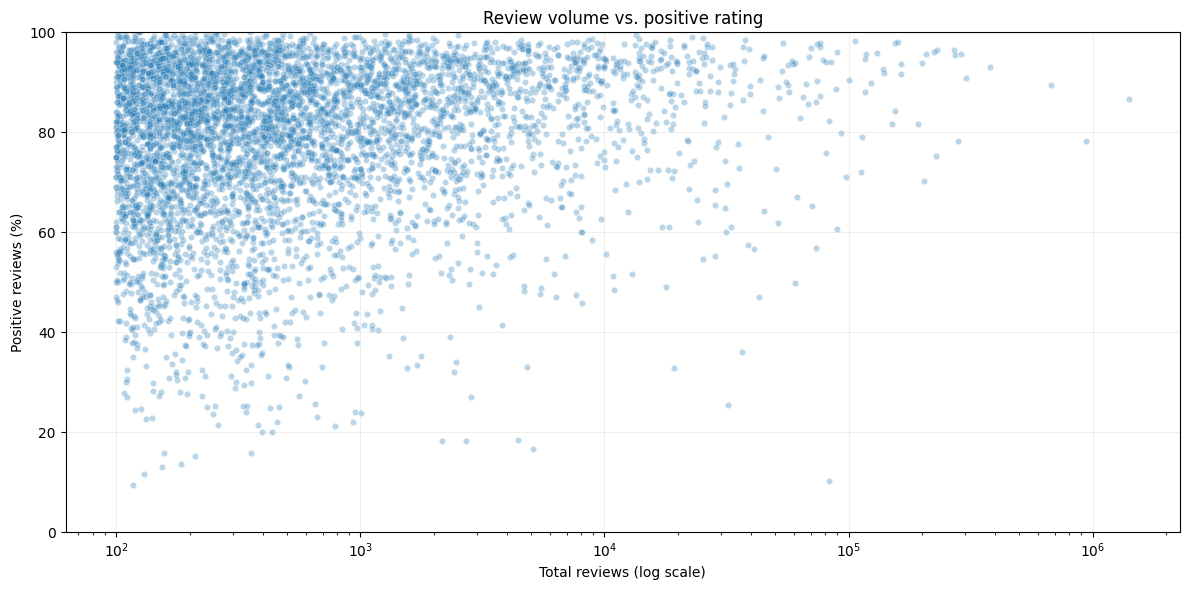

In [80]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_steam_100,
    x="total_reviews",
    y="positive_pct",
    alpha=0.3,
    s=20
)

plt.xscale("log")

plt.title("Review volume vs. positive rating")
plt.xlabel("Total reviews (log scale)")
plt.ylabel("Positive reviews (%)")

plt.ylim(0, 100)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [81]:
from scipy.stats import spearmanr

corr, p_value = spearmanr(
    df_steam_100["total_reviews"],
    df_steam_100["positive_pct"]
)

print("Spearman correlation:", round(corr, 4))
print("P-value:", p_value)

Spearman correlation: 0.1438
P-value: 6.732989301007431e-27


ρ = +0,1438, está cerca de cero.

Existe una asociación positiva débil entre el volumen de reseñas y el porcentaje positivo.

Es decir, en nuestra muestra de 5.518 videojuegos con al menos 100 reseñas, aquellos con más reseñas tienden a tener valoraciones ligeramente mejores.

Pero la relación es pequeña. Hay videojuegos con muchísimas reseñas y porcentajes positivos bajos, y otros con pocas reseñas y porcentajes positivos muy altos.

In [82]:
df_steam_100 = df_steam_100.copy()

df_steam_100["review_volume"] = pd.cut(
    df_steam_100["total_reviews"],
    bins=[100, 500, 1000, 5000, 10000, float("inf")],
    labels=[
        "100–499",
        "500–999",
        "1K–4.9K",
        "5K–9.9K",
        "10K+"
    ],
    right=False
)

df_review_volume_summary = (
    df_steam_100
    .groupby("review_volume", observed=True)
    .agg(
        games_count=("appid", "nunique"),
        median_positive_pct=("positive_pct", "median"),
        mean_positive_pct=("positive_pct", "mean"),
        median_reviews=("total_reviews", "median")
    )
    .reset_index()
)

display(df_review_volume_summary.round(2))

,review_volume,games_count,median_positive_pct,mean_positive_pct,median_reviews
0,100–499,3219,81.16,77.51,200.0
1,500–999,775,82.07,79.33,683.0
2,1K–4.9K,1041,85.07,81.82,1872.0
3,5K–9.9K,203,88.53,84.07,7163.0
4,10K+,280,89.41,84.72,23012.5


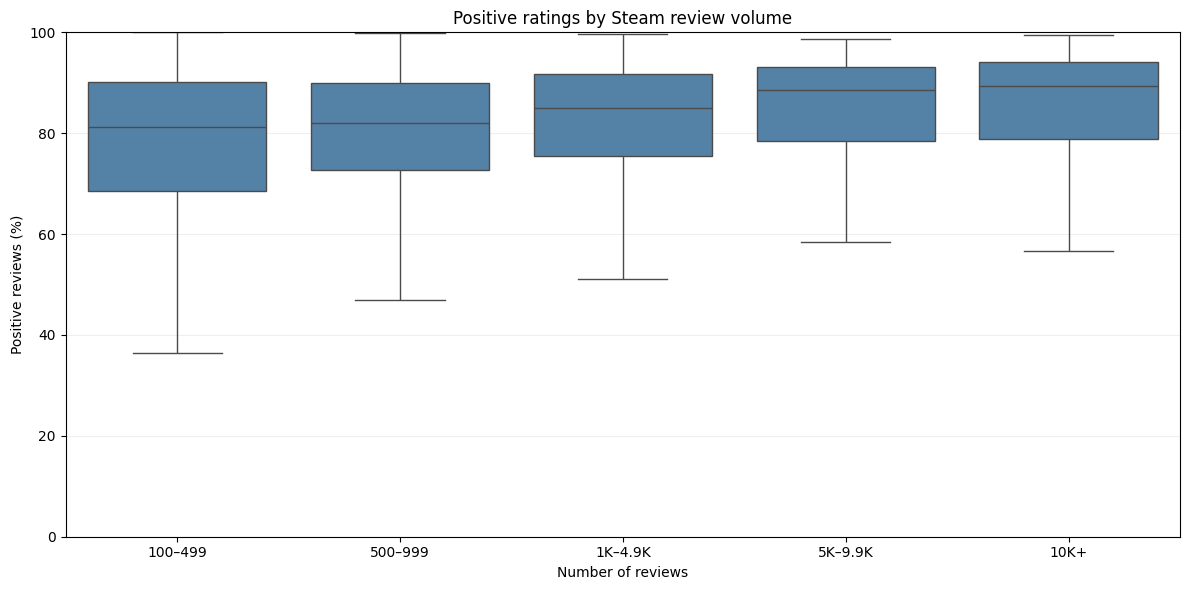

In [83]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_steam_100,
    x="review_volume",
    y="positive_pct",
    color="steelblue",
    showfliers=False
)

plt.title("Positive ratings by Steam review volume")
plt.xlabel("Number of reviews")
plt.ylabel("Positive reviews (%)")

plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [84]:
df_review_dispersion = (
    df_steam_100
    .groupby("review_volume", observed=True)["positive_pct"]
    .agg(
        q25=lambda x: x.quantile(0.25),
        median="median",
        q75=lambda x: x.quantile(0.75)
    )
)

df_review_dispersion["iqr"] = (
    df_review_dispersion["q75"]
    - df_review_dispersion["q25"]
)

display(df_review_dispersion.round(2))

,q25,median,q75,iqr
review_volume,,,,
100–499,68.57,81.16,90.07,21.51
500–999,72.62,82.07,89.97,17.35
1K–4.9K,75.43,85.07,91.74,16.31
5K–9.9K,78.43,88.53,93.11,14.68
10K+,78.93,89.41,94.19,15.26


Un mayor volúmen de reviews está asociado con mayor satisfacción del jugador.

Entre los 5.518 juegos analizados con al menos 100 reviews, la mediana de reviews positivos incrementa desde el 81.16& pra juegos con 100-499 reviews hasta un 89.41% para los juegos con más de 10.000 reviews. La relación es opsitiva pero débil (Spearman's ρ = 0.144, p < 0.001).

In [85]:
EDA_DIR = Path("eda_data")
IGDB_CLEAN = Path("eda_data") / "igdb_clean.parquet"
GAMES_CLEAN = Path("eda_data") / "games_clean.parquet"
STEAM_MAP_CLEAN = Path("eda_data") / "steam_map_clean.parquet"

df_igdb_clean = pd.read_parquet(IGDB_CLEAN)
df_games_clean = pd.read_parquet(GAMES_CLEAN)
df_steam_map_clean = pd.read_parquet(STEAM_MAP_CLEAN)

df_steam_map_clean.head()

,id,game,name,uid,url,year,external_game_source
0,1862340,371206,异星前线,1212320,https://store.steampowered.com/app/1212320,2020.0,1
1,2894452,298060,"Beat Saber - Daft Punk - ""One More Time""",2838290,https://store.steampowered.com/app/2838290,2024.0,1
2,2975535,331273,WET,3447390,https://store.steampowered.com/app/3447390,2025.0,1
3,2975616,330913,of the Devil - Episode 1,3124580,https://store.steampowered.com/app/3124580,2025.0,1
4,2959783,336169,Creeping Clark,3309240,https://store.steampowered.com/app/3309240,2025.0,1


In [86]:
# Correspondencias IGDB-Steam
df_mapping = (
    df_steam_map_clean[["game", "uid"]]
    .rename(columns={
        "game": "igdb_id",
        "uid": "appid"
    })
    .drop_duplicates()
    .copy()
)

df_mapping["igdb_id"] = pd.to_numeric(
    df_mapping["igdb_id"], errors="coerce"
)

df_mapping["appid"] = pd.to_numeric(
    df_mapping["appid"], errors="coerce"
)

df_mapping = df_mapping.dropna().astype({
    "igdb_id": "int64",
    "appid": "int64"
})

In [87]:
print("--- VALIDACIÓN DEL MAPPING ---")

print(
    "AppIDs asociados a varios juegos IGDB:",
    (df_mapping.groupby("appid")["igdb_id"].nunique() > 1).sum()
)

print(
    "Juegos IGDB asociados a varios AppIDs:",
    (df_mapping.groupby("igdb_id")["appid"].nunique() > 1).sum()
)

--- VALIDACIÓN DEL MAPPING ---
AppIDs asociados a varios juegos IGDB: 0
Juegos IGDB asociados a varios AppIDs: 1815


In [88]:
df_igdb_metadata = df_games_clean[
    [
        "id",
        "name",
        "release_year",
        "genres_clean",
        "is_indie",
        "platforms_names",
        "game_modes_names"
    ]
].rename(columns={
    "id": "igdb_id",
    "name": "game_name"
})

# Incorporar los IDs de IGDB a Steam
df_steam_igdb = (
    df_steam_eda
    .merge(
        df_mapping,
        on="appid",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        df_igdb_metadata,
        on="igdb_id",
        how="inner",
        validate="many_to_one"
    )
)

print("--- STEAM + IGDB ---")

print("AppIDs disponibles en Steam:", df_steam_eda["appid"].nunique())

print("AppIDs con metadatos IGDB:", df_steam_igdb["appid"].nunique())

print("Juegos IGDB únicos:", df_steam_igdb["igdb_id"].nunique())

print(
    "Juegos IGDB con varios AppIDs:",
    (
        df_steam_igdb.groupby("igdb_id")["appid"]
        .nunique().gt(1).sum()
    )
)

--- STEAM + IGDB ---
AppIDs disponibles en Steam: 27795
AppIDs con metadatos IGDB: 21350
Juegos IGDB únicos: 21346
Juegos IGDB con varios AppIDs: 4


In [89]:
df_multi_steam = (
    df_steam_igdb
    .groupby("igdb_id")
    .agg(
        game_name=("game_name", "first"),
        appid_count=("appid", "nunique"),
        total_reviews=("total_reviews", "sum")
    )
    .query("appid_count > 1")
    .sort_values("total_reviews", ascending=False)
)

display(df_multi_steam.head(15))

print(
    "Juegos IGDB con varios AppIDs:",
    len(df_multi_steam)
)

,game_name,appid_count,total_reviews
igdb_id,,,
143224,Project Sparrow,2,1177.0
151763,Rainbow Sea,2,42.0
159268,Elemental War 2,2,29.0
205656,Apocalyptic,2,2.0


Juegos IGDB con varios AppIDs: 4


In [90]:
df_steam_igdb_valid = df_steam_igdb.loc[
    df_steam_igdb["total_reviews"].ge(100)
    & df_steam_igdb["positive_pct"].between(0, 100)
].copy()

print(
    "AppIDs con 100+ reseñas y valoración válida:",
    len(df_steam_igdb_valid)
)

print(
    "Juegos IGDB únicos:",
    df_steam_igdb_valid["igdb_id"].nunique()
)

AppIDs con 100+ reseñas y valoración válida: 5388
Juegos IGDB únicos: 5388


In [91]:
df_steam_genres = (
    df_steam_igdb_valid[
        [
            "igdb_id",
            "appid",
            "game_name",
            "genres_clean",
            "total_reviews",
            "positive_pct"
        ]
    ]
    .explode("genres_clean")
    .dropna(subset=["genres_clean"])
    .rename(columns={"genres_clean": "genre"})
    .copy()
)

print("--- COBERTURA DE GÉNEROS EN STEAM ---")

print("Juegos totales:", len(df_steam_igdb_valid))
print("Juegos con género:", df_steam_genres["igdb_id"].nunique())
print("Géneros distintos:", df_steam_genres["genre"].nunique())

--- COBERTURA DE GÉNEROS EN STEAM ---
Juegos totales: 5388
Juegos con género: 5047
Géneros distintos: 22


In [92]:
df_steam_genre_summary = (
    df_steam_genres
    .groupby("genre")
    .agg(
        games_count=("igdb_id", "nunique"),
        median_positive_pct=("positive_pct", "median"),
        mean_positive_pct=("positive_pct", "mean"),
        median_reviews=("total_reviews", "median")
    )
    .reset_index()
)

# Filtrar géneros con al menos 100 videojuegos
df_steam_genre_summary = (
    df_steam_genre_summary.loc[
        df_steam_genre_summary["games_count"] >= 100
    ]
    .sort_values("median_positive_pct", ascending=False)
)

display(df_steam_genre_summary.round(2))

,genre,games_count,median_positive_pct,mean_positive_pct,median_reviews
21,Visual Novel,346,90.71,87.26,348.5
9,Point-and-click,272,88.71,85.53,361.0
10,Puzzle,726,87.92,84.12,421.5
1,Arcade,380,87.65,83.81,463.0
8,Platform,421,86.68,83.56,480.0
0,Adventure,2609,83.90,80.31,387.0
4,Hack and slash/Beat 'em up,133,83.28,78.16,934.0
2,Card & Board Game,115,82.54,78.47,434.0
15,Shooter,573,82.18,78.50,776.0
19,Tactical,141,80.93,78.50,1091.0


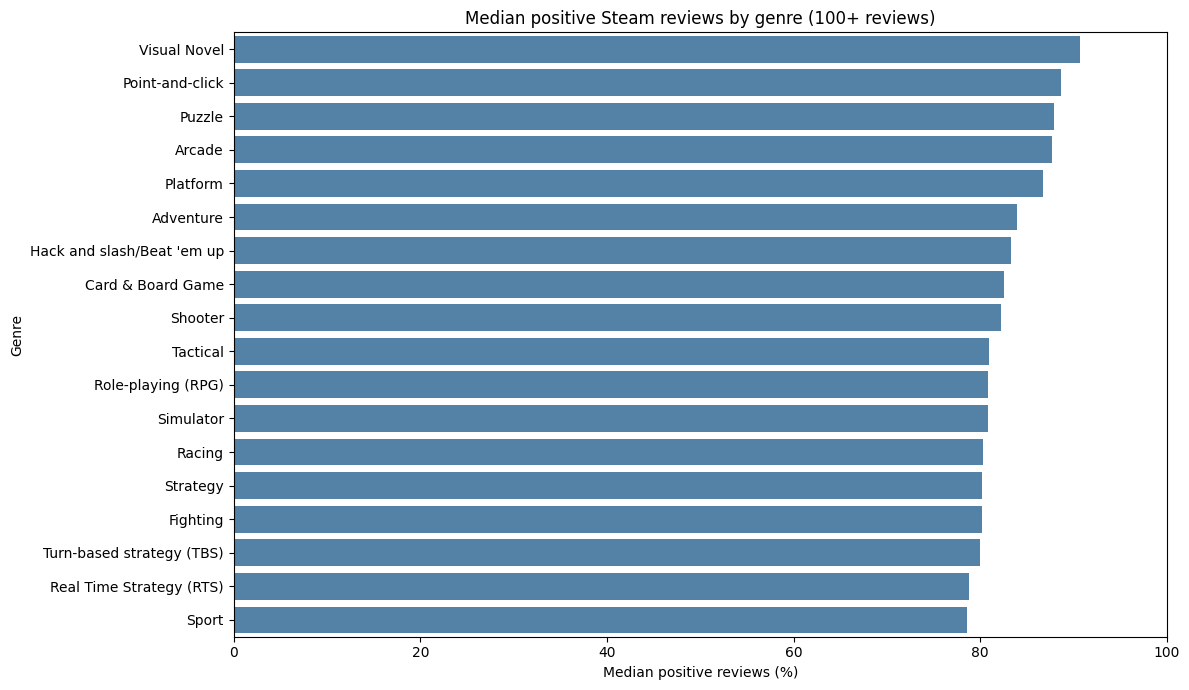

In [93]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=df_steam_genre_summary,
    x="median_positive_pct",
    y="genre",
    color="steelblue"
)

plt.title("Median positive Steam reviews by genre (100+ reviews)")
plt.xlabel("Median positive reviews (%)")
plt.ylabel("Genre")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

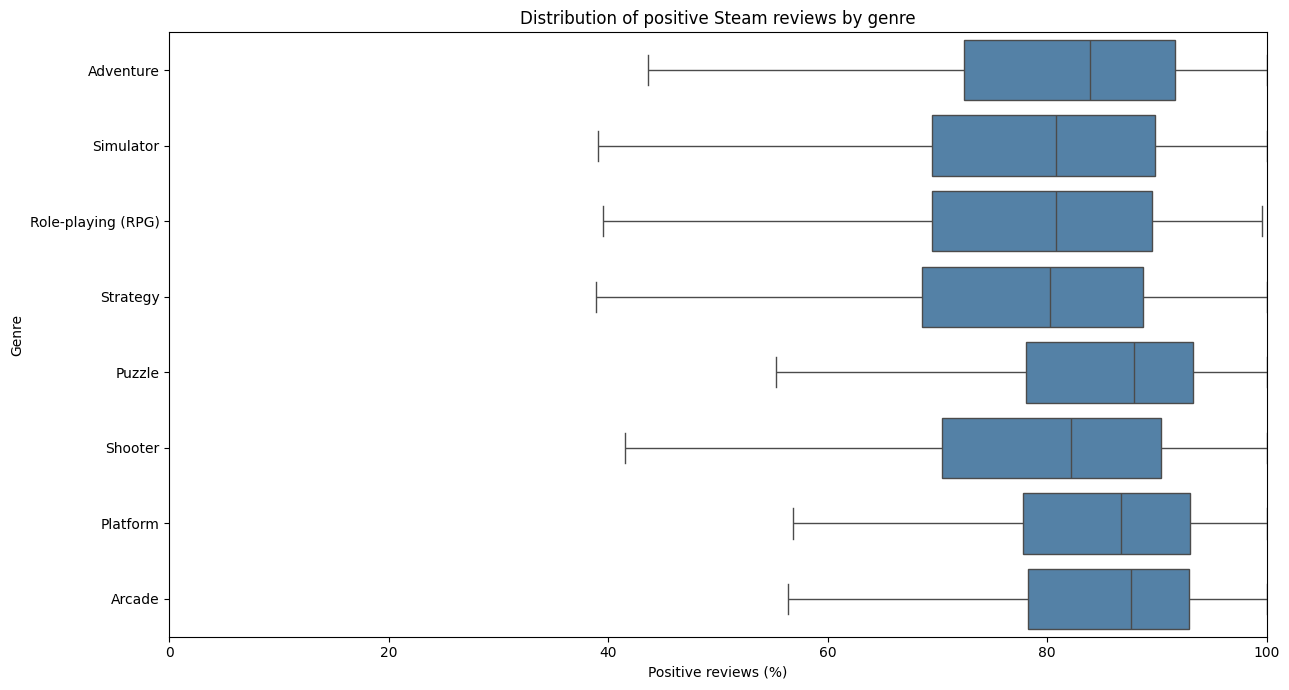

In [94]:
top_8_steam_genres = (
    df_steam_genres["genre"]
    .value_counts()
    .head(8)
    .index
)

df_steam_genres_top = df_steam_genres.loc[
    df_steam_genres["genre"].isin(top_8_steam_genres)
].copy()

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df_steam_genres_top,
    x="positive_pct",
    y="genre",
    order=list(top_8_steam_genres),
    color="steelblue",
    showfliers=False
)

plt.title("Distribution of positive Steam reviews by genre")
plt.xlabel("Positive reviews (%)")
plt.ylabel("Genre")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

Visual Novel ocupa la primera posición, con una mediana del 90,71 % de valoraciones positivas entre 346 videojuegos.

Le siguen Point-and-click (88,71 %), Puzzle (87,92 %) y Arcade (87,65 %).

Por otro lado, Strategy (80,22 %), Simulator (80,79 %) y RPG (80,79 %) presentan medianas inferiores.

Los géneros que más abundan en el catálogo no son necesariamente los mejor valorados.

Por ejemplo, Adventure es el género más frecuente, pero ocupa una posición intermedia en valoración.

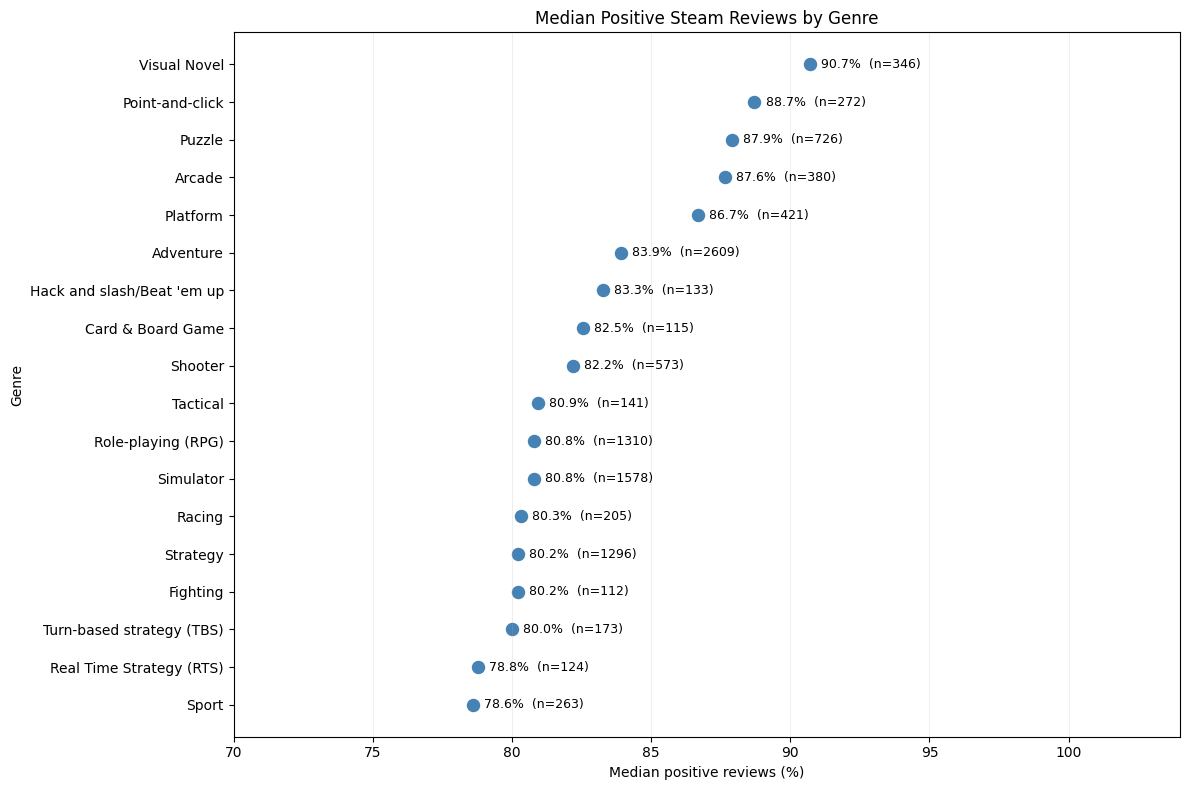

In [95]:
# Ordenar géneros por mediana
df_plot_genres = (
    df_steam_genre_summary
    .sort_values("median_positive_pct")
    .copy()
)

plt.figure(figsize=(12, 8))

plt.scatter(
    df_plot_genres["median_positive_pct"],
    df_plot_genres["genre"],
    s=75,
    color="steelblue"
)

# Añadir porcentaje y número de videojuegos
for _, row in df_plot_genres.iterrows():

    plt.text(
        row["median_positive_pct"] + 0.4,
        row["genre"],
        f'{row["median_positive_pct"]:.1f}%  (n={int(row["games_count"])})',
        va="center",
        fontsize=9
    )

plt.title("Median Positive Steam Reviews by Genre")
plt.xlabel("Median positive reviews (%)")
plt.ylabel("Genre")

plt.xlim(70, 104)
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

More Games Doesn't Necessarily Mean Better Ratings

Adventure is the most represented genre in the analyzed Steam catalogue, with 2,609 games, but Visual Novel has the highest median positive rating (90.71%), followed by Point-and-click (88.71%) and Puzzle (87.92%). This suggests that genre prevalence and player satisfaction do not necessarily follow the same pattern

# Indie vs. No Indie en Steam

In [96]:
df_steam_indie_summary = (
    df_steam_igdb_valid
    .groupby("is_indie")
    .agg(
        games_count=("igdb_id", "nunique"),
        median_positive_pct=("positive_pct", "median"),
        mean_positive_pct=("positive_pct", "mean"),
        median_reviews=("total_reviews", "median"),
        mean_reviews=("total_reviews", "mean")
    )
    .reset_index()
)

df_steam_indie_summary["category"] = (
    df_steam_indie_summary["is_indie"]
    .map({
        True: "Indie",
        False: "No Indie label"
    })
)

display(
    df_steam_indie_summary[
        [
            "category",
            "games_count",
            "median_positive_pct",
            "mean_positive_pct",
            "median_reviews",
            "mean_reviews"
        ]
    ].round(2)
)

,category,games_count,median_positive_pct,mean_positive_pct,median_reviews,mean_reviews
0,No Indie label,1566,79.37,76.10,464.5,6437.87
1,Indie,3822,84.08,80.64,354.0,2740.99


Los videojuegos etiquetados como Indie reciben, en general, mejores valoraciones positivas, mientras que los juegos sin esa etiqueta acumulan más reseñas.

Esto sugiere que, dentro de los videojuegos analizados, los títulos etiquetados como Indie tienden a recibir valoraciones más favorables.

La mediana de reseñas de los juegos sin etiqueta Indie es aproximadamente un 30% superior a la de los Indie.

Entre los 5388 juegos de Steam con al menos 100 reviews, los juegos etiquetados como Indie muestran una mediana de reseñas superior (84.08% vs. 79.37%), mientras que los juegos sin la etiqueta de Indie reciben más reviews (464.5 vs. 354 de mediana). Esto sugiere que un mayor número de reviews no se traduce necesariamente en una mayor satisfacción del jugador.

In [97]:
df_steam_indie_recent = (
    df_steam_igdb_valid.loc[
        df_steam_igdb_valid["release_year"].between(2016, 2025)
    ]
    .groupby("is_indie")
    .agg(
        games_count=("igdb_id", "nunique"),
        median_positive_pct=("positive_pct", "median"),
        mean_positive_pct=("positive_pct", "mean"),
        median_reviews=("total_reviews", "median"),
        mean_reviews=("total_reviews", "mean")
    )
    .reset_index()
)

df_steam_indie_recent["category"] = (
    df_steam_indie_recent["is_indie"]
    .map({
        True: "Indie",
        False: "No Indie label"
    })
)

display(
    df_steam_indie_recent[
        [
            "category",
            "games_count",
            "median_positive_pct",
            "mean_positive_pct",
            "median_reviews",
            "mean_reviews"
        ]
    ].round(2)
)

,category,games_count,median_positive_pct,mean_positive_pct,median_reviews,mean_reviews
0,No Indie label,961,78.96,76.03,423.0,7363.94
1,Indie,2878,84.41,81.20,349.0,2956.51


In [98]:
# Top 15 de todos los AppIDs de Steam
df_top15_steam = (
    df_steam_eda.loc[
        df_steam_eda["total_reviews"].notna()
    ]
    .sort_values("total_reviews", ascending=False)
    .head(15)
    .copy()
)

df_top15_steam["rank"] = range(1, 16)

# Incorporar metadatos IGDB cuando estén disponibles
metadata_cols = [
    "appid",
    "igdb_id",
    "game_name",
    "release_year",
    "genres_clean",
    "platforms_names",
    "game_modes_names",
    "is_indie"
]

df_top15_games = df_top15_steam.merge(
    df_steam_igdb[metadata_cols].drop_duplicates("appid"),
    on="appid",
    how="left",
    validate="one_to_one"
)

print("--- TOP 15 STEAM ---")
print("Juegos con metadatos IGDB:", df_top15_games["igdb_id"].notna().sum())
print("Juegos sin metadatos IGDB:", df_top15_games["igdb_id"].isna().sum())

--- TOP 15 STEAM ---
Juegos con metadatos IGDB: 15
Juegos sin metadatos IGDB: 0


In [99]:
def format_list_column(value):

    if isinstance(value, (list, tuple, np.ndarray)):

        if len(value) == 0:
            return "Unknown"

        return ", ".join(map(str, value))

    return "Unknown"

In [100]:
df_top15_display = df_top15_games.copy()

# Convertir listas en texto para visualizarlas
df_top15_display["genres"] = (
    df_top15_display["genres_clean"]
    .apply(format_list_column)
)

df_top15_display["platforms"] = (
    df_top15_display["platforms_names"]
    .apply(format_list_column)
)

df_top15_display["game_modes"] = (
    df_top15_display["game_modes_names"]
    .apply(format_list_column)
)

df_top15_display["indie_classification"] = (
    df_top15_display["is_indie"]
    .map({
        True: "Indie",
        False: "No Indie label"
    })
    .fillna("Unknown")
)

columns_top15 = [
    "rank",
    "game_name",
    "appid",
    "release_year",
    "genres",
    "platforms",
    "game_modes",
    "indie_classification",
    "total_reviews",
    "positive_pct"
]

display(
    df_top15_display[columns_top15]
    .round({"positive_pct": 2})
)

,rank,game_name,appid,release_year,genres,platforms,game_modes,indie_classification,total_reviews,positive_pct
0,1,Rust,252490,2018,"Shooter, Role-playing (RPG), Adventure","PC (Microsoft Windows), Mac","Multiplayer, Co-operative, Massively Multiplay...",Indie,1414080.0,86.64
1,2,Dead by Daylight,381210,2016,Strategy,"Google Stadia, Xbox Series X|S, PlayStation 4,...","Single player, Multiplayer, Co-operative",No Indie label,940429.0,78.30
2,3,Payday 2,218620,2013,"Shooter, Role-playing (RPG), Tactical","PlayStation 3, PlayStation 4, Linux, PC (Micro...","Single player, Multiplayer, Co-operative",No Indie label,675252.0,89.37
3,4,Raft,648800,2022,"Simulator, Adventure","Xbox Series X|S, PC (Microsoft Windows), PlayS...","Single player, Multiplayer, Co-operative",Indie,380076.0,92.97
4,5,Forza Horizon 4,1293830,2018,"Racing, Sport, Adventure","Xbox Series X|S, PC (Microsoft Windows), Xbox One","Single player, Multiplayer, Co-operative, Batt...",No Indie label,303560.0,90.87
5,6,Titanfall 2,1237970,2016,"Shooter, Adventure","PlayStation 4, PC (Microsoft Windows), Xbox One","Single player, Multiplayer, Co-operative",No Indie label,289249.0,95.67
6,7,The Finals,2073850,2023,Shooter,"Xbox Series X|S, PlayStation 4, PC (Microsoft ...","Multiplayer, Co-operative",No Indie label,281093.0,78.16
7,8,It Takes Two,1426210,2021,"Platform, Puzzle, Adventure","Xbox Series X|S, PlayStation 4, Nintendo Switc...","Multiplayer, Co-operative, Split screen",No Indie label,273523.0,95.44
8,9,Detroit: Become Human,1222140,2018,Adventure,"PlayStation 4, PC (Microsoft Windows)",Single player,No Indie label,270756.0,96.39
9,10,Doki Doki Literature Club!,698780,2017,"Adventure, Visual Novel","Linux, Android, PC (Microsoft Windows), iOS, Mac",Single player,Indie,230052.0,96.49


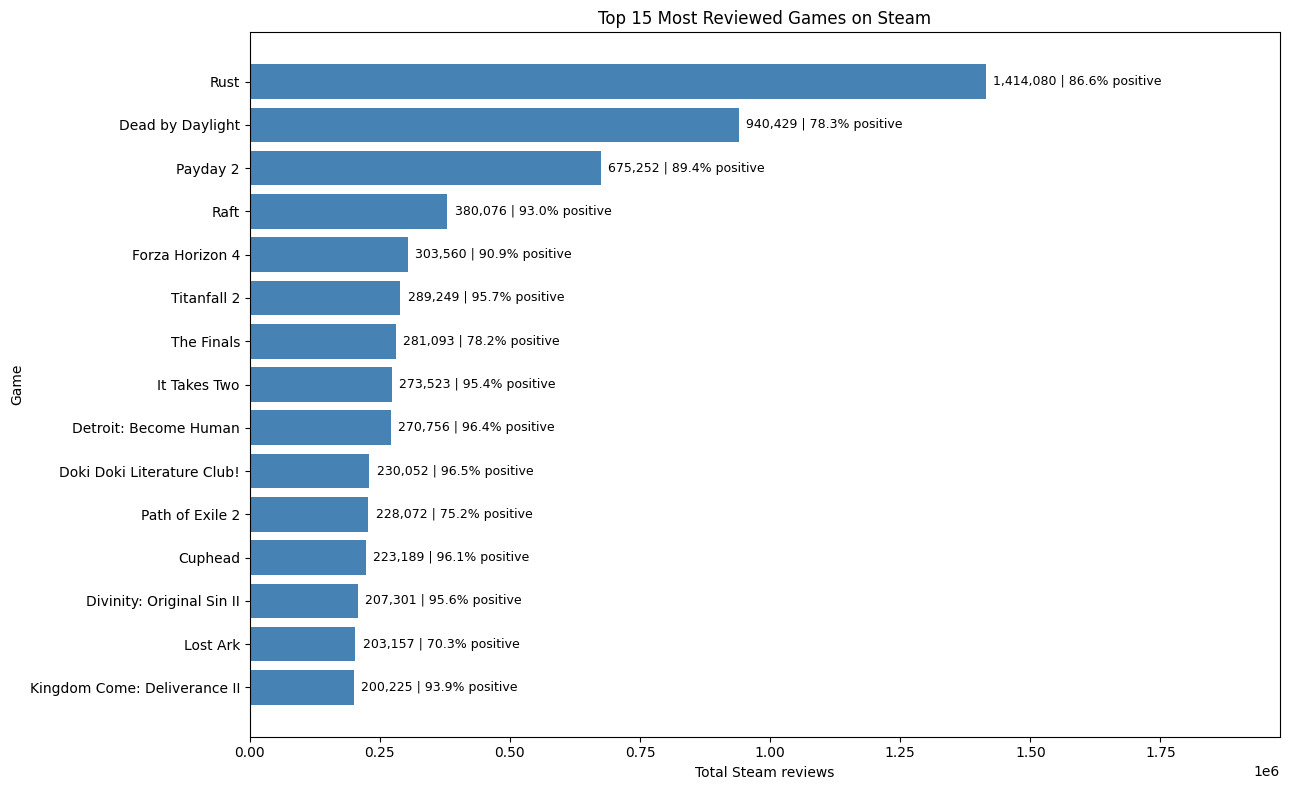

In [101]:
df_top15_plot = (
    df_top15_games
    .sort_values("total_reviews", ascending=True)
    .copy()
)

df_top15_plot["game_label"] = (
    df_top15_plot["game_name"]
    .fillna(
        "AppID " + df_top15_plot["appid"].astype(str)
    )
)

plt.figure(figsize=(13, 8))

bars = plt.barh(
    df_top15_plot["game_label"],
    df_top15_plot["total_reviews"],
    color="steelblue"
)

for bar, (_, row) in zip(bars, df_top15_plot.iterrows()):

    positive = row["positive_pct"]

    label = (
        f"{row['total_reviews']:,.0f} | {positive:.1f}% positive"
        if pd.notna(positive)
        else f"{row['total_reviews']:,.0f}"
    )

    plt.text(
        bar.get_width() + df_top15_plot["total_reviews"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center",
        fontsize=9
    )

plt.title("Top 15 Most Reviewed Games on Steam")
plt.xlabel("Total Steam reviews")
plt.ylabel("Game")

plt.xlim(
    0,
    df_top15_plot["total_reviews"].max() * 1.4
)

plt.tight_layout()
plt.show()

In [102]:
print("--- TOP 15: CARACTERÍSTICAS ---")

print(
    "Total de reseñas acumuladas:",
    f"{df_top15_games['total_reviews'].sum():,.0f}"
)

print(
    "Mediana de valoración positiva:",
    round(df_top15_games["positive_pct"].median(), 2),
    "%"
)

print(
    "Juegos etiquetados Indie:",
    df_top15_games["is_indie"].eq(True).sum()
)

print(
    "Juegos sin etiqueta Indie:",
    df_top15_games["is_indie"].eq(False).sum()
)

print(
    "Año más antiguo:",
    df_top15_games["release_year"].min()
)

print(
    "Año más reciente:",
    df_top15_games["release_year"].max()
)

--- TOP 15: CARACTERÍSTICAS ---
Total de reseñas acumuladas: 6,120,014
Mediana de valoración positiva: 92.97 %
Juegos etiquetados Indie: 4
Juegos sin etiqueta Indie: 11
Año más antiguo: 2013
Año más reciente: 2025


In [103]:
df_top15_genres = (
    df_top15_games
    .explode("genres_clean")
    .dropna(subset=["genres_clean"])
)

display(
    df_top15_genres["genres_clean"]
    .value_counts()
    .rename_axis("genre")
    .reset_index(name="games_count")
)

,genre,games_count
0,Adventure,12
1,Role-playing (RPG),6
2,Shooter,5
3,Strategy,2
4,Simulator,2
5,Platform,2
6,Hack and slash/Beat 'em up,2
7,Tactical,1
8,Racing,1
9,Sport,1


In [104]:
df_top15_modes = (
    df_top15_games
    .explode("game_modes_names")
    .dropna(subset=["game_modes_names"])
)

display(
    df_top15_modes["game_modes_names"]
    .value_counts()
    .rename_axis("game_mode")
    .reset_index(name="games_count")
)

,game_mode,games_count
0,Multiplayer,12
1,Co-operative,12
2,Single player,12
3,Massively Multiplayer Online (MMO),3
4,Battle Royale,1
5,Split screen,1


In [105]:
df_top15_modes_summary = (
    df_top15_games
    .explode("game_modes_names")
    .dropna(subset=["game_modes_names"])
    ["game_modes_names"]
    .value_counts()
    .rename_axis("game_mode")
    .reset_index(name="games_count")
)

df_top15_modes_summary["percentage"] = (
    df_top15_modes_summary["games_count"]
    / len(df_top15_games)
    * 100
).round(2)

display(df_top15_modes_summary)

,game_mode,games_count,percentage
0,Multiplayer,12,80.00
1,Co-operative,12,80.00
2,Single player,12,80.00
3,Massively Multiplayer Online (MMO),3,20.00
4,Battle Royale,1,6.67
5,Split screen,1,6.67


Aunque los videojuegos Single player representan la mayoría de los lanzamientos, los títulos Multiplayer podrían concentrar una parte desproporcionada de la atención de los jugadores.

#######################################################

# EDA ITAD

In [106]:
EDA_DIR = Path("eda_data")
ITAD_DIR = Path("itad_etl")
ITAD_PARQUET_DIR = ITAD_DIR / "parquet_history"

# Metadatos de videojuegos
df_games_clean = pd.read_parquet(
    EDA_DIR / "games_clean.parquet"
)

# Resumen de reseñas de Steam
df_steam_eda = pd.read_parquet(
    EDA_DIR / "steam_reviews_summary.parquet"
)

# Mapping IGDB - Steam
df_steam_map_clean = pd.read_parquet(
    EDA_DIR / "steam_map_clean.parquet"
)

# Información resumida de ITAD
df_itad_overview = pd.read_csv(
    ITAD_DIR / "itad_overview.csv"
)

print("--- DATASETS ---")
print("IGDB:", df_games_clean.shape)
print("Steam:", df_steam_eda.shape)
print("Mapping:", df_steam_map_clean.shape)
print("ITAD Overview:", df_itad_overview.shape)

--- DATASETS ---
IGDB: (236126, 21)
Steam: (27795, 7)
Mapping: (181352, 7)
ITAD Overview: (105460, 16)


In [107]:
con = duckdb.connect()

itad_path = (
    ITAD_PARQUET_DIR / "appid_*_part_*.parquet"
).as_posix()

con.execute(f"""
    CREATE OR REPLACE VIEW itad_history AS
    SELECT *
    FROM read_parquet(
        '{itad_path}',
        union_by_name = true
    )
""")

print("Vista ITAD creada correctamente")

Vista ITAD creada correctamente


In [108]:
print("--- COLUMNAS HISTÓRICO ITAD ---")

display(
    con.execute("""
        DESCRIBE itad_history
    """).df()
)

print("--- EJEMPLOS ---")

display(
    con.execute("""
        SELECT *
        FROM itad_history
        LIMIT 5
    """).df()
)

--- COLUMNAS HISTÓRICO ITAD ---


,column_name,column_type,null,key,default,extra
0,timestamp,VARCHAR,YES,None,None,None
1,shop_id,BIGINT,YES,None,None,None
2,shop_name,VARCHAR,YES,None,None,None
3,deal_price_amount,DOUBLE,YES,None,None,None
4,deal_price_amountInt,BIGINT,YES,None,None,None
5,deal_price_currency,VARCHAR,YES,None,None,None
6,deal_regular_amount,DOUBLE,YES,None,None,None
7,deal_regular_amountInt,BIGINT,YES,None,None,None
8,deal_regular_currency,VARCHAR,YES,None,None,None
9,deal_cut,BIGINT,YES,None,None,None


--- EJEMPLOS ---


,timestamp,shop_id,shop_name,deal_price_amount,deal_price_amountInt,deal_price_currency,deal_regular_amount,deal_regular_amountInt,deal_regular_currency,deal_cut,appid
0,2026-11-02T19:38:38+01:00,61,Steam,10.25,1025,EUR,10.25,1025,EUR,0,1000000
1,2026-10-26T22:01:02+01:00,61,Steam,1.53,153,EUR,10.25,1025,EUR,85,1000000
2,2026-10-08T22:13:13+02:00,61,Steam,10.25,1025,EUR,10.25,1025,EUR,0,1000000
3,2026-10-01T21:44:10+02:00,61,Steam,1.53,153,EUR,10.25,1025,EUR,85,1000000
4,2026-07-09T20:44:29+02:00,61,Steam,10.25,1025,EUR,10.25,1025,EUR,0,1000000


In [109]:
df_itad_overview_stats = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT appid) AS total_games,
        MIN(timestamp) AS first_record,
        MAX(timestamp) AS last_record
    FROM itad_history
""").df()

display(df_itad_overview_stats)

,total_records,total_games,first_record,last_record
0,2404760,21088,2012-02-18T08:04:22+01:00,2026-11-21T12:27:04+01:00


In [110]:
# Comprobamos la distribución de monedas
df_itad_currencies = con.execute("""
    SELECT
        deal_price_currency AS currency,
        COUNT(*) AS records,
        COUNT(DISTINCT appid) AS games
    FROM itad_history
    GROUP BY deal_price_currency
    ORDER BY records DESC
""").df()

display(df_itad_currencies)

,currency,records,games
0,EUR,2336041,21087
1,USD,44840,1341
2,GBP,23878,792
3,CHF,1,1


In [111]:
# Comprobaremos la distribución por tiendas
df_itad_shops = con.execute("""
    SELECT
        shop_name,
        COUNT(*) AS records,
        COUNT(DISTINCT appid) AS games
    FROM itad_history
    GROUP BY shop_name
    ORDER BY records DESC
""").df()

display(df_itad_shops.head(20))

,shop_name,records,games
0,Steam,820454,20985
1,Fanatical,249186,1999
2,Humble Store,159658,1724
3,GamersGate,114403,1429
4,GOG,104646,917
5,GameBillet,74195,967
6,IndieGala Store,69744,1460
7,GreenManGaming,69449,1670
8,eTail.Market,66010,405
9,WinGameStore,58309,1175


In [112]:
# Creamos el dataset de descuentos de Steam
con.execute("""
    CREATE OR REPLACE VIEW itad_steam_eur AS
    SELECT
        appid,
        TRY_CAST(timestamp AS TIMESTAMPTZ) AS price_date,
        deal_price_amount AS price,
        deal_regular_amount AS regular_price,
        deal_cut AS discount_pct
    FROM itad_history
    WHERE shop_name = 'Steam'
      AND deal_price_currency = 'EUR'
      AND deal_regular_currency = 'EUR'
      AND deal_cut BETWEEN 0 AND 100
      AND deal_price_amount >= 0
      AND deal_regular_amount > 0
      AND deal_price_amount <= deal_regular_amount
""")

In [113]:
df_itad_steam_coverage = con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT appid) AS total_games,
        MIN(price_date) AS first_record,
        MAX(price_date) AS last_record,
        COUNT(*) FILTER (
            WHERE discount_pct > 0
        ) AS discounted_records
    FROM itad_steam_eur
""").df()

display(df_itad_steam_coverage)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_records,total_games,first_record,last_record,discounted_records
0,816455,18443,2012-09-04 22:23:30+02:00,2026-11-21 00:15:31+01:00,397722


In [114]:
df_itad_steam_coverage["discounted_records_pct"] = (
    df_itad_steam_coverage["discounted_records"]
    / df_itad_steam_coverage["total_records"]
    * 100
)

display(df_itad_steam_coverage)

,total_records,total_games,first_record,last_record,discounted_records,discounted_records_pct
0,816455,18443,2012-09-04 22:23:30+02:00,2026-11-21 00:15:31+01:00,397722,48.713279


In [115]:
# Cuadro resumen de descuentos por videojuego (AppID)
df_itad_discounts = con.execute("""
    SELECT
        appid,

        COUNT(*) AS total_records,

        COUNT(*) FILTER (
            WHERE discount_pct > 0
        ) AS discount_records,

        MAX(discount_pct) AS max_discount_pct,

        AVG(discount_pct) AS mean_discount_pct,

        MIN(price) AS min_price_eur,

        MAX(regular_price) AS max_regular_price_eur,

        MIN(price_date) AS first_price_date,

        MAX(price_date) AS last_price_date

    FROM itad_steam_eur

    GROUP BY appid
""").df()

df_itad_discounts["discount_record_share_pct"] = (
    df_itad_discounts["discount_records"]
    / df_itad_discounts["total_records"]
    * 100
)

print("--- DATASET DESCUENTOS ---")
print("Videojuegos:", len(df_itad_discounts))

display(df_itad_discounts.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

--- DATASET DESCUENTOS ---
Videojuegos: 18443


,appid,total_records,discount_records,max_discount_pct,mean_discount_pct,min_price_eur,max_regular_price_eur,first_price_date,last_price_date,discount_record_share_pct
0,1058040,1,1,33,33.000000,2.20,3.29,2019-08-01 10:10:41+02:00,2019-08-01 10:10:41+02:00,100.0
1,1126020,30,15,90,33.500000,0.39,3.99,2019-09-09 14:07:09+02:00,2025-07-10 19:48:18+02:00,50.0
2,1389470,2,1,10,5.000000,5.12,5.69,2020-09-08 04:49:14+02:00,2020-09-14 19:22:11+02:00,50.0
3,2713950,25,13,75,22.600000,1.24,7.32,2024-06-13 21:48:12+02:00,2026-10-08 21:17:56+02:00,52.0
4,2775180,64,32,51,25.328125,0.49,0.99,2024-01-25 13:37:45+01:00,2026-10-19 19:37:39+02:00,50.0


In [116]:
# Validamos la distribución de descuentos
print("--- DESCUENTO MÁXIMO HISTÓRICO ---")

display(
    df_itad_discounts["max_discount_pct"].describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

--- DESCUENTO MÁXIMO HISTÓRICO ---


count    18443.000000
mean        55.421298
std         26.673390
min          0.000000
10%         15.000000
25%         35.000000
50%         60.000000
75%         80.000000
90%         90.000000
95%         90.000000
99%         94.580000
max        100.000000
Name: max_discount_pct, dtype: float64

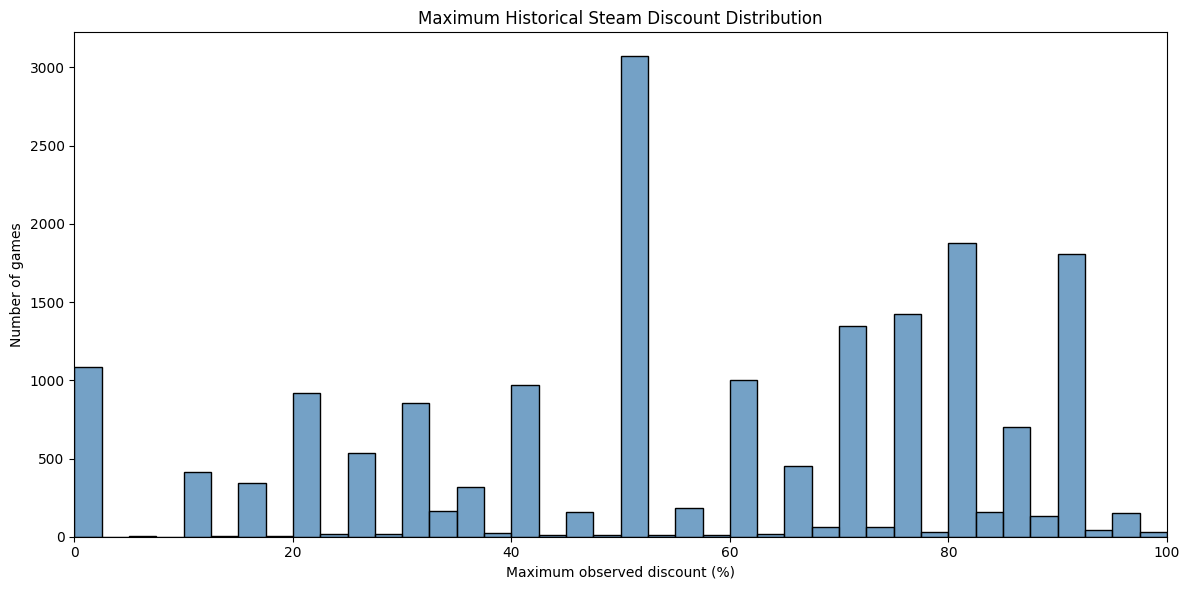

In [117]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_itad_discounts,
    x="max_discount_pct",
    bins=40,
    color="steelblue"
)

plt.title("Maximum Historical Steam Discount Distribution")
plt.xlabel("Maximum observed discount (%)")
plt.ylabel("Number of games")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [118]:
EDA_DIR = Path("eda_data")
EDA_DIR.mkdir(parents=True, exist_ok=True)

df_itad_discounts.to_parquet(
    EDA_DIR / "itad_steam_discounts_summary.parquet",
    index=False
)

print("Archivo guardado correctamente")

Archivo guardado correctamente


El descuento máximo mediano es del 60 %. La mitad de los juegos ha registrado un descuento máximo igual o superior a ese porcentaje.

El 25 % de los videojuegos ha alcanzado descuentos máximos del 80 % o superiores, ya que el tercer cuartil es 80 %.

Los descuentos parecen concentrarse en determinados valores comerciales: 50 %, 75 %, 80 %, 90 %, etc.

In [119]:
# Agrupamos los videojuegos por tramos de descuento
discount_bins = [-0.1, 0, 24, 49, 74, 100]

discount_labels = [
    "No discount",
    "Low (1–24%)",
    "Moderate (25–49%)",
    "High (50–74%)",
    "Very high (75–100%)"
]

df_itad_discounts["discount_category"] = pd.cut(
    df_itad_discounts["max_discount_pct"],
    bins=discount_bins,
    labels=discount_labels
)

df_discount_distribution = (
    df_itad_discounts["discount_category"]
    .value_counts(sort=False)
    .reset_index()
)

df_discount_distribution.columns = [
    "discount_category",
    "games_count"
]

df_discount_distribution["percentage"] = (
    df_discount_distribution["games_count"]
    / len(df_itad_discounts)
    * 100
).round(2)

display(df_discount_distribution)

,discount_category,games_count,percentage
0,No discount,1088,5.90
1,Low (1–24%),1709,9.27
2,Moderate (25–49%),3069,16.64
3,High (50–74%),6215,33.70
4,Very high (75–100%),6362,34.50


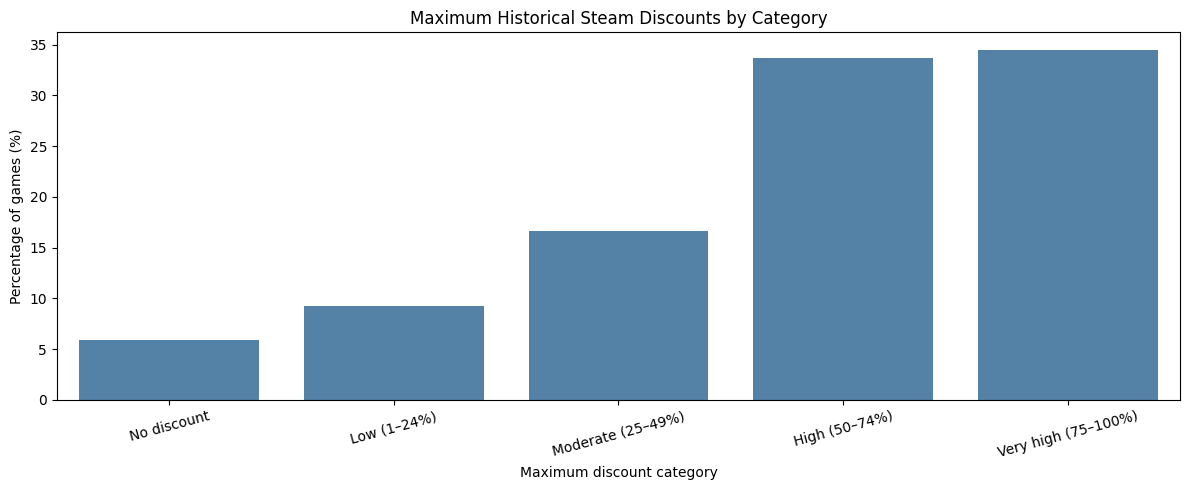

In [120]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df_discount_distribution,
    x="discount_category",
    y="percentage",
    color="steelblue"
)

plt.title("Maximum Historical Steam Discounts by Category")
plt.xlabel("Maximum discount category")
plt.ylabel("Percentage of games (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [121]:
# Correspondencia entre IGDB y Steam
df_mapping = (
    df_steam_map_clean[["game", "uid"]]
    .rename(columns={
        "game": "igdb_id",
        "uid": "appid"
    })
    .drop_duplicates()
    .copy()
)

df_mapping = df_mapping.dropna(
    subset=["igdb_id", "appid"]
)

df_mapping["appid"] = df_mapping["appid"].astype("int64")
df_mapping["igdb_id"] = df_mapping["igdb_id"].astype("int64")

# Incorporar metadatos
df_itad_igdb = (
    df_itad_discounts
    .merge(
        df_mapping,
        on="appid",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        df_games_clean[
            ["id", "name", "release_year", "is_indie", "genres_clean"]
        ].rename(columns={
            "id": "igdb_id",
            "name": "game_name"
        }),
        on="igdb_id",
        how="inner",
        validate="many_to_one"
    )
)

print("--- ITAD + IGDB ---")
print("AppIDs:", df_itad_igdb["appid"].nunique())
print("Juegos IGDB:", df_itad_igdb["igdb_id"].nunique())

--- ITAD + IGDB ---
AppIDs: 17688
Juegos IGDB: 17688


In [122]:
# Calculamos la antigüedad
reference_date = pd.Timestamp("2026-11-21")

df_itad_igdb["game_age"] = (
    reference_date.year
    - df_itad_igdb["release_year"].astype(int)
)

# Descartar edades negativas si las hubiera
df_itad_igdb = df_itad_igdb.loc[
    df_itad_igdb["game_age"] >= 0
].copy()

display(
    df_itad_igdb[
        [
            "game_name",
            "release_year",
            "game_age",
            "max_discount_pct",
            "discount_category"
        ]
    ].head()
)

,game_name,release_year,game_age,max_discount_pct,discount_category
0,My University Story,2019,7,33,Moderate (25–49%)
1,Wizard Battle,2019,7,90,Very high (75–100%)
2,The Snare,2024,2,75,Very high (75–100%)
3,101 Cats,2024,2,51,High (50–74%)
4,Gaming Cafe Life,2024,2,40,Moderate (25–49%)


In [123]:
age_bins = [-1, 1, 3, 5, 10, float("inf")]

age_labels = [
    "0–1 years",
    "2–3 years",
    "4–5 years",
    "6–10 years",
    "10+ years"
]

df_itad_igdb["age_group"] = pd.cut(
    df_itad_igdb["game_age"],
    bins=age_bins,
    labels=age_labels
)

In [124]:
df_discount_by_age = (
    df_itad_igdb
    .groupby("age_group", observed=True)
    .agg(
        games_count=("appid", "nunique"),
        median_discount=("max_discount_pct", "median"),
        mean_discount=("max_discount_pct", "mean"),
        median_records=("total_records", "median")
    )
    .reset_index()
)

display(df_discount_by_age.round(2))

,age_group,games_count,median_discount,mean_discount,median_records
0,0–1 years,4335,40.0,40.64,10.0
1,2–3 years,3578,51.0,53.91,28.0
2,4–5 years,2723,70.0,60.55,44.0
3,6–10 years,5519,70.0,62.85,45.0
4,10+ years,1533,80.0,73.28,94.0


Entre los videojuegos más recientes y los más antiguos observamos una diferencia de 40 puntos porcentuales.

También resulta interesante que el mayor incremento aparece durante los primeros cinco años. Después, las medianas parecen estabilizarse alrededor del 70 %, hasta alcanzar el 80 % entre los juegos con más de una década.

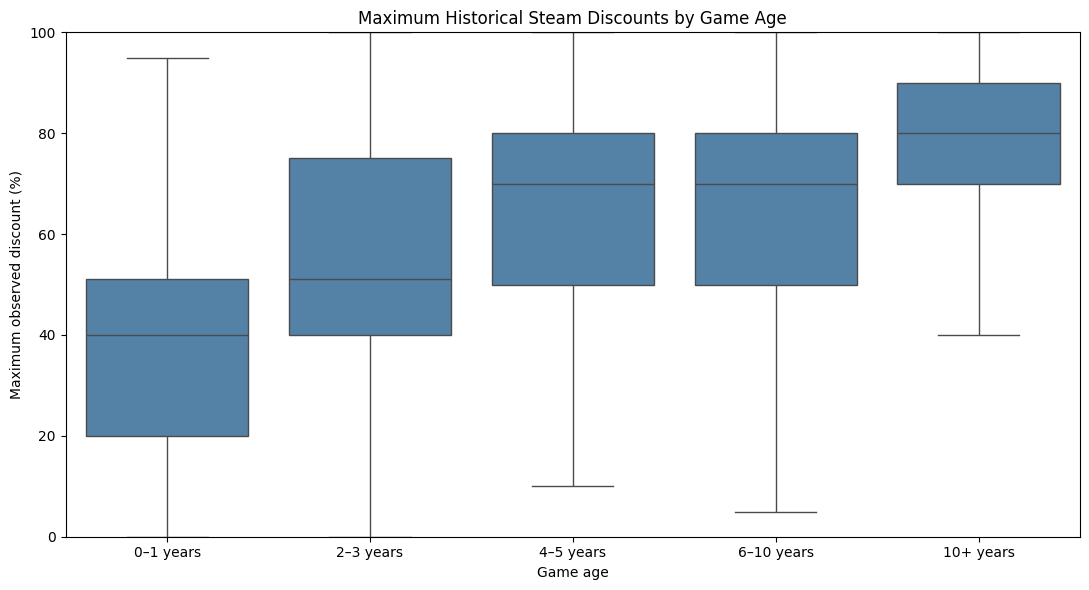

In [125]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_itad_igdb,
    x="age_group",
    y="max_discount_pct",
    color="steelblue",
    showfliers=False
)

plt.title("Maximum Historical Steam Discounts by Game Age")
plt.xlabel("Game age")
plt.ylabel("Maximum observed discount (%)")

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [126]:
corr, p_value = spearmanr(
    df_itad_igdb["game_age"],
    df_itad_igdb["max_discount_pct"],
    nan_policy="omit"
)

print("--- CORRELACIÓN ANTIGÜEDAD VS DESCUENTO ---")

print("Spearman:", round(corr, 4))
print("P-value:", p_value)

--- CORRELACIÓN ANTIGÜEDAD VS DESCUENTO ---
Spearman: 0.4049
P-value: 0.0


La correlación de Spearman respalda la tendencia

Spearman: antigüedad frente a descuento máximo

ρ = +0,4049

Asociación positiva moderada · 17.688 observaciones

In [127]:
df_itad_igdb["history_days"] = (
    pd.to_datetime(
        df_itad_igdb["last_price_date"],
        utc=True
    )
    - pd.to_datetime(
        df_itad_igdb["first_price_date"],
        utc=True
    )
).dt.days

display(
    df_itad_igdb["history_days"].describe()
)

count    17688.000000
mean      1272.062867
std       1213.047541
min          0.000000
25%        299.000000
50%        878.000000
75%       1959.000000
max       5159.000000
Name: history_days, dtype: float64

Los videojuegos más antiguos tienden a alcanzar descuentos mayores en Steam.

El análisis de 17.688 videojuegos con metadatos de IGDB e históricos de precios de Steam muestra una asociación positiva moderada entre la antigüedad y el descuento máximo observado (Spearman ρ = 0,405; p < 0,001). La mediana del descuento máximo pasa del 40 % en videojuegos de 0–1 años al 80 % en títulos con más de una década. Sin embargo, esta asociación puede estar parcialmente influida por la duración y cobertura de los históricos disponibles.

In [128]:
# comprobar el efecto de la duración del historial

variables = [
    "game_age",
    "history_days",
    "total_records"
]

results = []

for variable in variables:

    df_valid = df_itad_igdb[
        [variable, "max_discount_pct"]
    ].dropna()

    rho, p_value = spearmanr(
        df_valid[variable],
        df_valid["max_discount_pct"]
    )

    results.append({
        "variable": variable,
        "games": len(df_valid),
        "spearman_rho": rho,
        "p_value": p_value
    })

df_discount_correlations = pd.DataFrame(results)

display(df_discount_correlations.round(4))

,variable,games,spearman_rho,p_value
0,game_age,17688,0.4049,0.0
1,history_days,17688,0.6240,0.0
2,total_records,17688,0.6572,0.0


El descuento máximo observado está más asociado con la cantidad y duración de los datos históricos disponibles que con la antigüedad del videojuego.

Esto tiene sentido por una razón estadística: cuantos más registros de precios observamos, mayores son las oportunidades de encontrar un descuento elevado.

Imagina dos videojuegos que alguna vez han alcanzado un descuento del 90 %:
- Del primero tenemos 200 registros históricos.
- Del segundo tenemos únicamente 5 registros.
Es mucho más probable que nuestro dataset haya capturado el descuento máximo del primero.

Por tanto, el descuento máximo no depende únicamente de las políticas de precios, sino también de nuestra capacidad para observarlas.

Eso sí, estas correlaciones no demuestran que la duración del historial explique por sí sola la relación entre antigüedad y descuentos. Las tres variables podrían estar relacionadas entre sí.

Los videojuegos más antiguos presentan descuentos máximos superiores, aunque la cobertura del historial influye considerablemente en esta relación.

Entre 17.688 videojuegos analizados, la antigüedad muestra una correlación positiva moderada con el descuento máximo registrado (ρ = 0,405). Sin embargo, la duración del historial disponible (ρ = 0,624) y el número de observaciones (ρ = 0,657) presentan asociaciones aún mayores. Esto sugiere que las diferencias en la cobertura histórica deben considerarse antes de atribuir los descuentos exclusivamente a la antigüedad de los videojuegos.

# Cruce ITAD, IGDB y Steam

In [129]:
df_steam_eda["positive_pct"] = (
    df_steam_eda["total_positive"]
    / df_steam_eda["total_reviews"]
    * 100
)

# Los juegos sin reseñas no tienen valoración positiva calculable
df_steam_eda.loc[
    df_steam_eda["total_reviews"].le(0),
    "positive_pct"
] = np.nan

print("--- VALIDACIÓN STEAM ---")

print("AppIDs:", df_steam_eda["appid"].nunique())

print(
    "Con porcentaje positivo válido:",
    df_steam_eda["positive_pct"].between(0, 100).sum()
)

display(
    df_steam_eda[
        ["appid", "total_reviews", "total_positive",
         "total_negative", "positive_pct"]
    ].head()
)

--- VALIDACIÓN STEAM ---
AppIDs: 27795
Con porcentaje positivo válido: 20291


,appid,total_reviews,total_positive,total_negative,positive_pct
0,1000000,43.0,35.0,8.0,81.395349
1,1000040,1.0,0.0,1.0,0.000000
2,1000300,NaN,NaN,NaN,NaN
3,1000360,8615.0,7605.0,1010.0,88.276262
4,1000380,406.0,320.0,86.0,78.817734


In [130]:
steam_columns = [
    "appid",
    "total_reviews",
    "total_positive",
    "total_negative",
    "positive_pct"
]

df_itad_steam = df_itad_igdb.merge(
    df_steam_eda[steam_columns],
    on="appid",
    how="inner",
    validate="one_to_one"
)

print("--- COBERTURA DE LAS 3 APIs ---")

print("Videojuegos con las 3 fuentes:", len(df_itad_steam))

print(
    "Con al menos 100 reseñas:",
    (df_itad_steam["total_reviews"] >= 100).sum()
)

--- COBERTURA DE LAS 3 APIs ---
Videojuegos con las 3 fuentes: 17200
Con al menos 100 reseñas: 4375


In [131]:
df_discount_ratings = df_itad_steam.loc[
    df_itad_steam["total_reviews"].ge(100)
    & df_itad_steam["positive_pct"].between(0, 100)
    & df_itad_steam["max_discount_pct"].between(0, 100)
].copy()

print("--- DATASET DE ANÁLISIS ---")

print("Videojuegos:", len(df_discount_ratings))
print("AppIDs únicos:", df_discount_ratings["appid"].nunique())

display(
    df_discount_ratings[
        [
            "game_name",
            "release_year",
            "total_reviews",
            "positive_pct",
            "max_discount_pct",
            "history_days"
        ]
    ].head()
)

--- DATASET DE ANÁLISIS ---
Videojuegos: 4375
AppIDs únicos: 4375


,game_name,release_year,total_reviews,positive_pct,max_discount_pct,history_days
3,101 Cats,2024,266.0,85.714286,51,998
4,Gaming Cafe Life,2024,153.0,94.771242,40,903
5,Shift 87,2024,219.0,86.301370,50,807
6,"Girls on Campus, from Freshmen to Faculty, All...",2024,382.0,69.371728,66,783
7,True Nightmare: Roadside Сafe,2025,149.0,79.865772,30,468


In [132]:
rho, p_value = spearmanr(
    df_discount_ratings["positive_pct"],
    df_discount_ratings["max_discount_pct"]
)

print("--- VALORACIONES VS DESCUENTOS ---")

print("Spearman:", round(rho, 4))
print("P-value:", p_value)

--- VALORACIONES VS DESCUENTOS ---
Spearman: -0.2965
P-value: 1.657665368684666e-89


Los datos muestran una asociación negativa entre las valoraciones positivas de Steam y el descuento máximo histórico registrado en ITAD.

Es decir, los videojuegos mejor valorados tienden a haber recibido descuentos máximos menores.

El p-value obtenido es 1,66 × 10⁻⁸⁹, muy inferior a 0,001. Esto aporta evidencia estadística contra la hipótesis de ausencia de asociación monótona, aunque no demuestra causalidad.

En términos prácticos, significa que, en los videojuegos analizados, un porcentaje positivo más elevado tiende a coincidir con un descuento máximo inferior.

In [133]:
rating_bins = [0, 20, 40, 70, 90, 100.0001]

rating_labels = [
    "Muy negativas",
    "Mayormente negativas",
    "Mixtas",
    "Mayormente positivas",
    "Muy positivas"
]

df_discount_ratings["rating_category"] = pd.cut(
    df_discount_ratings["positive_pct"],
    bins=rating_bins,
    labels=rating_labels,
    right=False,
    include_lowest=True
)

df_discount_by_rating = (
    df_discount_ratings
    .groupby("rating_category", observed=True)
    .agg(
        games_count=("appid", "nunique"),
        median_discount=("max_discount_pct", "median"),
        mean_discount=("max_discount_pct", "mean"),
        median_history_days=("history_days", "median"),
        median_game_age=("game_age", "median")
    )
    .reset_index()
)

display(df_discount_by_rating.round(2))

,rating_category,games_count,median_discount,mean_discount,median_history_days,median_game_age
0,Muy negativas,8,65.0,55.00,2491.0,11.5
1,Mayormente negativas,85,80.0,71.73,2553.0,10.0
2,Mixtas,880,80.0,70.57,2155.5,8.0
3,Mayormente positivas,2216,70.0,62.90,1826.0,6.0
4,Muy positivas,1186,50.0,52.87,1352.0,4.0


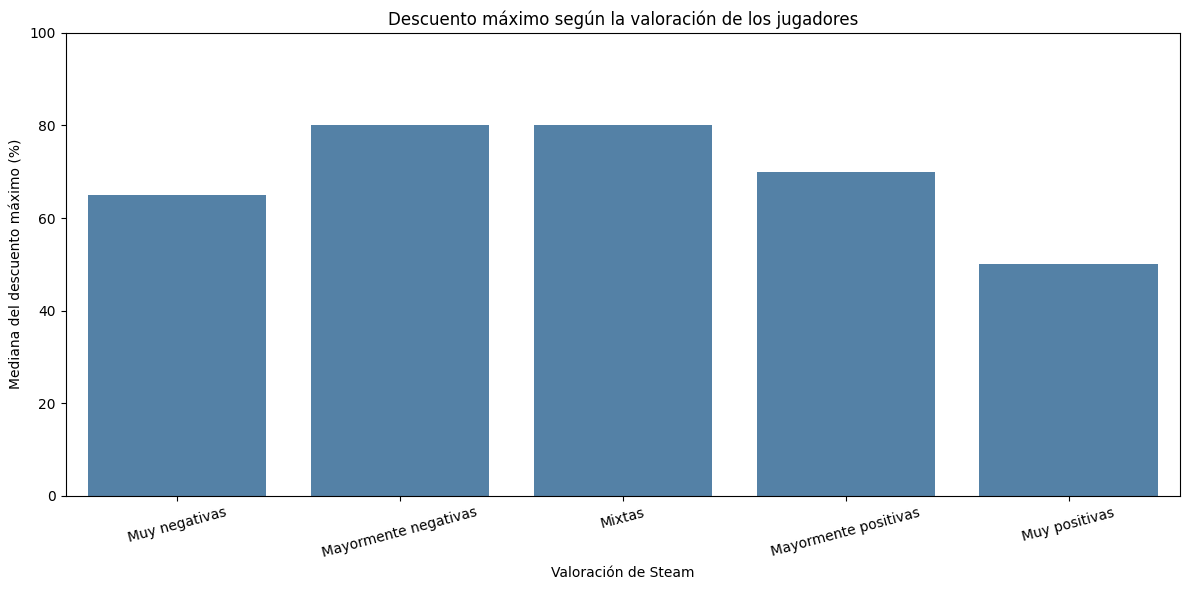

In [134]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_discount_by_rating,
    x="rating_category",
    y="median_discount",
    color="steelblue"
)

plt.title("Descuento máximo según la valoración de los jugadores")
plt.xlabel("Valoración de Steam")
plt.ylabel("Mediana del descuento máximo (%)")

plt.xticks(rotation=15)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

Los videojuegos mejor valorados son, en términos medianos, más recientes y tienen menos historial disponible.

Y ya habíamos comprobado que:
- Antigüedad vs. descuento: ρ = +0,4049.
- Duración del historial vs. descuento: ρ = +0,6240.
- Número de registros vs. descuento: ρ = +0,6572.
Por tanto, todavía no podemos afirmar que las buenas valoraciones estén relacionadas de manera independiente con descuentos menores.

Podría ocurrir que los videojuegos mejor valorados tengan descuentos máximos inferiores simplemente porque son más recientes y hemos observado menos promociones a lo largo de su vida.

Los videojuegos mejor valorados en Steam tienden a presentar descuentos máximos históricos inferiores.

Encontramos una asociación negativa estadísticamente significativa entre el porcentaje de valoraciones positivas y el mayor descuento observado (Spearman ρ = −0,297; p < 0,001). Los videojuegos con valoraciones muy positivas presentan un descuento máximo mediano del 50 %, frente al 80 % de los títulos con valoraciones mixtas. Sin embargo, los juegos mejor valorados también son más recientes y cuentan con historiales de precios más cortos, por lo que todavía no podemos atribuir esa diferencia a las valoraciones.